[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/15_Smart_Grid_Power_System_Attacks/FQML_SmartGridAttack_Addo2025.ipynb)

# Federated quantum machine learning for smart-grid cyber-attack detection: Addo, Kabeya and Ojo (2025) step by step

**Paper.** Kwabena Addo, Musasa Kabeya and Evans Eshiemogie Ojo, *Federated Quantum Machine Learning for Distributed Cybersecurity in Multi-Agent Energy Systems*, **Energies 2025, 18(20), 5418**, MDPI, published 14 October 2025. DOI: <https://doi.org/10.3390/en18205418>.

**What this notebook does.** Ten simulated energy-system agents each hold a private slice of labelled power-system measurements. Every agent trains the same 8-qubit variational quantum classifier (amplitude encoding, hardware-efficient ansatz of 10 layers, 240 rotation angles, ADAM with learning rate 0.01, 5 local epochs). A server collects the agents' parameter updates, which carry Laplace noise (the paper's differential-privacy step), and combines them with a coordinate-wise **trimmed mean** that discards the 2 largest and 2 smallest value of every coordinate, so that 2 Byzantine agents cannot wreck the model. The notebook then re-creates the paper's experiments: convergence under clean and adversarial conditions, the baseline table (FQML versus FedProx and SCAFFOLD), the amplitude-versus-angle encoding ablation, the privacy-utility trade-off, the circuit-depth sweep, robustness against an FGSM-style perturbation, the number-of-agents sweep, the communication cost, and it closes with a verdict for every number the paper reports.

**Important: the paper's data are not public.** The authors used a *synthetic* smart-grid telemetry set (100,000 samples, 20 features) and an *IEEE 39-bus* case study whose data they do not release ("contact the corresponding author"). This notebook therefore runs on the closest **public, real, labelled** dataset of the same kind: the **Mississippi State University / Oak Ridge National Laboratory power-system attack dataset** (phasor-measurement-unit, relay and Snort-log measurements of a real two-line power-system test bed with injected false-data, command-injection and relay-setting attacks). Because the data differ, the paper's *absolute* accuracies cannot be expected to carry over; the verdicts below say so explicitly.

**How to run.** Open in Colab (badge above), choose *Runtime -> Change runtime type -> CPU*, then *Runtime -> Run all*. `FAST_MODE = True` (default, configuration cell) reaches the end in roughly 10 to 15 minutes on a free Colab CPU runtime (16 minutes on a heavily shared laptop CPU) with reduced budgets: 1 seed, 10 rounds, 64 rows per agent, two-point sweeps. `FAST_MODE = False` (3 seeds, 20 rounds, 96 rows per agent, all sweeps, agent-number study) was started but **not completed for the committed version** (it was stopped after about 70 minutes on a CPU that was shared with other jobs, with the main experiments still running; expect two hours or more); the committed outputs are those of the `FAST_MODE = True` run, so every number below comes from 1 seed and 10 rounds and the paper-versus-notebook verdicts must be read with that in mind. A session restart may be needed after the first install cell. No GPU, no quantum hardware, no account and no API key are needed (the dataset is public and not gated, so the Hugging Face token below is not used).

**What you get at the end.** Plots of the real grid measurements, the drawn 8-qubit circuits that are actually simulated, the paper's figures re-drawn from this notebook's own runs, and a paper-versus-notebook table with a verdict per claim, followed by a critical reading and five exercises.

## The paper in one page

**Problem.** Multi-agent smart-energy systems (distributed energy resources, IoT devices, control agents) are attacked through false-data injection (FDI), denial of service (DoS) and coordinated multi-agent attacks. Centralised ML detectors expose raw data and are single points of failure; classical federated learning (FL) is limited in expressiveness and vulnerable to Byzantine agents and poisoning. The paper proposes **FQML**: local variational quantum classifiers (VQC) + differentially-private parameter exchange + robust (trimmed-mean) aggregation.

**Decision.** Binary per measurement vector: 0 = benign, 1 = malicious.

**Method.**
1. Agent *i* holds a private set $D_i=\{(x_j,y_j)\}$, $x_j\in\mathbb R^{20}$ (Eq. 1, 6). $N=10$ agents, $M_i=10{,}000$ samples each.
2. Local model: $f(x;\theta)=\sigma\big(\langle 0|U^\dagger(x,\theta)\,O\,U(x,\theta)|0\rangle\big)$ (Eq. 17) with $U=\prod_{l=1}^{L}\big[U_{ent}^{(l)}\prod_{k=1}^{q}R_z R_y R_x\big]U_{enc}(x)$ (Eq. 18): $q=8$ qubits, $L=10$ layers, hardware-efficient ansatz, nearest-neighbour CNOTs, 240 trainable angles, **amplitude encoding** (angle encoding as ablation, inputs $\ell_2$-normalised resp. scaled to $[-\pi,\pi]$), binary cross-entropy loss (Eq. 9).
3. Federated round (Algorithm A1, Eq. 19-23): broadcast $\theta$; each agent trains locally (ADAM, learning rate 0.01, 5 local epochs, batch 32); adds Laplace noise $\mathrm{Lap}(0,\sigma)$ with $\sigma=0.01$ (Eq. 25) to what it sends; the server applies the **trimmed mean** excluding the top and bottom $t=2$ values per coordinate and updates $\theta$.
4. Threat model: $t=2$ Byzantine agents (falsified updates) and $\epsilon$-bounded FGSM-style input perturbations $\tilde x=x+\delta,\ \|\delta\|\le\epsilon$ (Eq. 4, 14).
5. Simulator: Qiskit Aer statevector (noise-free); 100 rounds, 5 seeds, mean $\pm$ std.

**Claims that a rerun can test (numbers from the paper).**
* Abstract / Sec. 7.1 / Fig. 3: clean accuracy $\ge 96.3\%$ (about 95% in the text), about **88%** under adversarial perturbation, degradation $\le 7\%$.
* Table 1 (IEEE 39-bus, 5 seeds): FQML ACC 96.1 / precision 95.5 / recall 94.9 / F1 95.2 / AUC 0.968; FedProx 93.2 / 91.8 / 90.7 / 91.2 / 0.946; SCAFFOLD 92.4 / 91.2 / 90.3 / 90.7 / 0.941.
* Table 2: amplitude encoding ACC 96.2, F1 95.1, AUC 0.973 versus angle encoding 94.7, 93.8, 0.964 (amplitude +1.5 points).
* Fig. 12: FQML 96% clean / 93% adversarial, the highest of {classical FL, centralised QML, local QML, FedProx, SCAFFOLD} with the smallest degradation.
* Fig. 17: AUC 0.96. Fig. 9/10: accuracy above 85% even for strict privacy budgets, plateau beyond $\epsilon\approx 4$. Fig. 18: accuracy improves with depth and saturates at 8 to 10 layers. Fig. 8: above 90% for low-to-moderate perturbation, graceful decline. Fig. 11: accuracy drops by less than 3% from 5 to 80 agents. Sec. 5.5: converges to $\le 1\%$ loss 38% faster than the classical counterpart. Abstract / Fig. 4: about 500 KB per round, 28.6% less communication than classical FL. Fig. 13: smooth degradation under depolarising / damping / readout noise.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | synthetic smart-grid telemetry, 100,000 samples, $d=20$ (voltage, frequency, load, labelled FDI / DoS / coordinated attacks), not released; IEEE 39-bus case study, not released | **Mississippi State / ORNL power-system attack dataset** (public, real test-bed measurements, 128 columns, 15 files; downloaded and SHA-256 checked). `# CHOICE:` benign = *no-event* normal operation (scenario 41), malicious = any attack scenario; natural-fault scenarios are excluded from the main task and used as an extra, harder test. |
| Features | $d=20$ | median imputation -> `QuantileTransformer` (normal) -> `PCA(20)`, all fitted on the training sample only. `# CHOICE:` quantile transform instead of plain standardisation (chosen on a validation split below). |
| Samples | $M_i=10{,}000$ per agent, 100,000 in total | `N_PER_AGENT` = 64 (fast) / 96 (full) class-balanced rows per agent, 640 / 960 in total. A CPU statevector simulator that needs one forward and one adjoint pass per mini-batch cannot use 100,000 rows. |
| Split | not stated | stratified row-level split of files 0-9 (70% pool / 30% *row test*); files 10-14 are never seen and form the *file test*; *natural-fault test* = attack rows vs natural-fault rows of files 10-14. |
| Agents | $N=10$ (5 to 80 in the scalability study) | $N=10$; independent identically distributed, class-balanced shards (the paper says "distributed equally"); scalability study 5 / 10 / 20 agents. |
| Qubits, depth, parameters | 8 qubits, $L=10$, 240 angles | same: `RX`, `RY`, `RZ` on each qubit per layer (applied in this order, Eq. 18), then CNOT(0,1), CNOT(1,2), ..., CNOT(6,7) |
| Amplitude encoding | 20 features on 8 qubits (256 amplitudes) | the 20 PCA scores are zero-padded to 256 amplitudes and $\ell_2$-normalised (`qml.AmplitudeEmbedding(pad_with=0, normalize=True)`). `# CHOICE:` padding with zeros. |
| Angle encoding | $d$ rotations, data re-uploading when $d>q$, scaled to $[-\pi,\pi]$ | features 1-8: `RY` on qubits 0-7, features 9-16: `RX` on qubits 0-7, features 17-20: `RY` on qubits 0-3, all before the ansatz. `# CHOICE:` rotation axes of the re-uploaded chunks. |
| Observable | "a measurement observable $O$" | `# CHOICE:` Pauli-Z on one qubit, picked from {0, 3, 7} on a validation split (section 6) |
| Output | $\sigma(\langle O\rangle)$, BCE | the same: $p=\sigma(\langle Z\rangle)$ (range $[0.27,0.73]$), class = attack when $\langle Z\rangle>0$; AUC from $\langle Z\rangle$ |
| Initialisation | not stated | `# CHOICE:` $\theta\sim\mathcal N(0,0.1^2)$ |
| Local training | ADAM $\alpha=0.01$, $\beta=(0.9,0.999)$, $E=5$, batch 32 | same; fresh ADAM state for every agent in every round (stateless agents) |
| Update sent | "gradient" $\Delta\theta^{(i)}$ (Eq. 19-21) | `# CHOICE:` the parameter *difference* $\theta_i^{local}-\theta^{global}$ after the local epochs (a local-gradient-step sum); server step size 1 |
| Differential privacy | Laplace noise, $\sigma_i=0.01$ (Eq. 25); $\sigma_i=S_i/\epsilon_i$ with clipping for the $\epsilon$ sweep | main runs: $\sigma=0.01$, no clipping. $\epsilon$ sweep: every coordinate of the update clipped to $[-S,S]$ with $S=0.05$ (`# CHOICE:`), noise $\mathrm{Lap}(0,S/\epsilon)$. Per-coordinate clipping does **not** give a formal $\epsilon$-DP guarantee for the whole 240-dimensional update; the label "$\epsilon$" is the paper's calibration rule only. |
| Byzantine agents | $t=2$, "falsified gradient updates" | `# CHOICE:` 2 of 10 agents send $-5\times$ their honest update (sign flip with gain 5) |
| Aggregation | trimmed mean, $t=2$ | coordinate-wise trimmed mean, drops 2 largest and 2 smallest of 10 |
| Input attack | $\ell_p$-bounded, FGSM-inspired, $\epsilon$ not stated | `# CHOICE:` white-box FGSM on the test inputs in PCA space, $\delta=\epsilon\,\sigma_k\,\mathrm{sign}(\nabla_x\ell)$ with $\sigma_k$ the training standard deviation of feature $k$, headline $\epsilon=0.1$ (a first run with 0.25 drove every model below chance, so the headline was lowered; the whole sweep 0 to 1 is shown) |
| "Adversarial condition" | not defined precisely (FDI / poisoning / Byzantine) | **Byzantine-trained model attacked by FGSM at test time**; the two components are also reported separately |
| Baselines | classical FL, centralised QML, local QML, FedProx, SCAFFOLD (no details) | classical FL = FedAvg of a 20-16-1 tanh MLP (353 parameters); FedProx ($\mu=0.1$); SCAFFOLD (option II); centralised QML = same VQC on the pooled data with batch $N\times32$ and the same number of ADAM steps; local QML = each agent trains alone. All on the same 20 PCA features. Additionally FedAvg + the same DP + trimmed mean (a fair classical twin of FQML), and FQML with plain mean aggregation (to isolate the aggregator). |
| Positive class | malicious | attack = 1 (precision, recall, F1, FPR, FNR as in Eq. 26-28) |
| Simulator | Qiskit Aer statevector 0.45 | an exact batched NumPy statevector simulator with an adjoint gradient, **asserted equal to the PennyLane `default.qubit` QNode** (outputs and gradients) in section 7; training would take days with one circuit per sample per parameter shift |
| Rounds / seeds | 100 rounds, 5 seeds | `ROUNDS` (10 fast / 20 full), `RUN_SEEDS` (1 fast / 3 full) |
| Noise study (Fig. 13), real hardware | depolarising / damping / readout error | **not run** (needs density-matrix training of 8 qubits and 240 angles); no IBM token is used |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, subprocess, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_missing = [m for m in ("pennylane", "py7zr", "requests") if importlib.util.find_spec(m) is None]
if IN_COLAB or _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "py7zr", "requests"])
    print("Installed. If Colab complains about numpy, use Runtime > Restart session and run all cells again.")
else:
    print("All packages already available; skipping install.")

All packages already available; skipping install.


## 1. Configuration

Every tunable constant lives in the next cell. The *paper* column of the comments gives the paper's value; the full path cannot reach all of them on a CPU (100 rounds x 10,000 samples per agent x 5 seeds x ~15 runs would take weeks with a simulator that evaluates one circuit batch per ADAM step), so the budgets are trimmed and the trimming is stated.

In [2]:
import os
from pathlib import Path

FAST_MODE = True     # True: 10-15 minutes, 1 seed, 10 rounds, small sweeps.  False: 3 seeds, 20 rounds, every sweep (not completed for the committed version; two hours or more).
SEED = 42            # global seed (data split, sampling, PCA, ...); every run additionally has its own seed from RUN_SEEDS
IBM_TOKEN = ""       # unused: the paper evaluates simulators only, there is no real-hardware cell

# ---- values taken from the paper (Table A1, Sec. 6) ----
N_AGENTS     = 10      # paper: N = 10 (5 to 80 in the scalability study)
D_FEAT       = 20      # paper: d = 20 features
N_QUBITS     = 8       # paper: q = 8
N_LAYERS     = 10      # paper: L = 10 -> 8 x 3 x 10 = 240 trainable angles
LOCAL_EPOCHS = 5       # paper: E = 5
BATCH        = 32      # paper: batch 32
LR           = 0.01    # paper: ADAM, alpha = 0.01, beta = (0.9, 0.999)
DP_SIGMA     = 0.01    # paper Eq. 25: Laplace(0, 0.01)
TRIM_T       = 2       # paper: trimmed mean drops the top / bottom t = 2
BYZ_T        = 2       # paper: t = 2 Byzantine agents
# ---- choices the paper leaves open (marked `# CHOICE:` where they are used) ----
BYZ_GAIN     = 5.0     # CHOICE: a Byzantine agent sends -BYZ_GAIN x its honest update
INIT_SCALE   = 0.1     # CHOICE: theta ~ N(0, INIT_SCALE^2)
DP_CLIP      = 0.05    # CHOICE: per-coordinate clip S used in the epsilon sweep (sigma = S / epsilon)
ATTACK_EPS   = 0.1     # CHOICE: headline FGSM size in units of the training std of each PCA feature (0.25 in a first run drove every model below chance, so it was lowered; the sweep shows all sizes)
EPS_ADV_GRID = [0.0, 0.05, 0.1, 0.25, 0.5, 1.0]
N_TRAIN_FILES = 10     # files 0-9 -> training / validation / row test; files 10-14 are never seen in training
VAL_N = 600

# ---- budgets that depend on FAST_MODE ----
if FAST_MODE:
    N_PER_AGENT = 64            # paper: 10,000 rows per agent
    ROUNDS      = 10            # paper: 100
    RUN_SEEDS   = [0]           # paper: 5 seeds
    SWEEP_ROUNDS = 6
    DP_EPS_GRID = [0.5, 8.0]
    DEPTH_GRID  = [2, 10]
    AGENT_GRID  = []            # skipped in the fast path
    DESIGN_STEPS = 60
    N_TEST_ROW, N_TEST_FILE, N_TEST_NAT = 600, 600, 600
else:
    N_PER_AGENT = 96
    ROUNDS      = 20
    RUN_SEEDS   = [0, 1, 2]
    SWEEP_ROUNDS = 12
    DP_EPS_GRID = [0.5, 1.0, 2.0, 4.0, 8.0]
    DEPTH_GRID  = [2, 4, 6, 8, 10]
    AGENT_GRID  = [5, 20]       # N = 10 is the main run
    DESIGN_STEPS = 120
    N_TEST_ROW, N_TEST_FILE, N_TEST_NAT = 800, 1000, 1000
MAX_AGENTS = max([N_AGENTS] + AGENT_GRID)
DATA_DIR = Path(os.environ.get("QC163_DATA_DIR", "qc163_data"))   # downloaded archives are cached here
print(f"FAST_MODE={FAST_MODE} | agents={N_AGENTS} x {N_PER_AGENT} rows | rounds={ROUNDS} | seeds={RUN_SEEDS} | sweeps: eps={DP_EPS_GRID} depth={DEPTH_GRID} agents={AGENT_GRID}")

FAST_MODE=True | agents=10 x 64 rows | rounds=10 | seeds=[0] | sweeps: eps=[0.5, 8.0] depth=[2, 10] agents=[]


In [3]:
import time, io, glob, shutil, hashlib, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches
import requests
import sklearn
import scipy
import pennylane as qml
from pennylane import numpy as pnp
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, QuantileTransformer, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
np.random.seed(SEED)
rng_global = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
T_START = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| pennylane", qml.__version__)

# Hugging Face token handling (required by the repository rules). This dataset is NOT on Hugging Face and is not gated, so the
# token is never used here. If you swap in a gated mirror, store your own token in Colab Secrets as HF_TOKEN; never paste it here.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2 | pennylane 0.45.1


## 2. Data: download, verify, pool

The Mississippi State University / Oak Ridge National Laboratory *power-system attack datasets* (Hink et al.; Pan, Morris, Adhikari) record 128 measurements per time step on a test bed with two generators, four breakers, two lines and four phasor measurement units (PMUs): the phasor magnitudes and angles of voltages and currents, relay and control-panel fields and Snort intrusion-detection log fields. The recorded **scenarios** are normal operation (*no events*), natural events (short-circuit faults, line maintenance) and cyber-attacks (data injection, remote tripping command injection, relay setting change). The *binary* release (15 CSV files, 78,377 rows) labels every row `Natural` or `Attack`; the *multiclass* release of the same rows carries the scenario number 1 to 41. We use the binary release for the task and the multiclass release only to separate *no events* from *natural events* and to colour the plots.

The archives are 7z files hosted at the University of Alabama in Huntsville; the original address is sometimes offline, so a Wayback Machine copy of the same file is the fallback. Both archives are verified by SHA-256 and unpacked only for the moment it takes to read them into memory (the CSVs are about 80 MB).

In [4]:
ARCHIVES = {
    "binary": dict(
        file="binaryAllNaturalPlusNormalVsAttacks.7z",
        sha256="b02c16bd74374d782298767708453570e4bc85e6a6e176c56a9c552358d472f8",
        urls=["http://www.ece.uah.edu/~thm0009/icsdatasets/binaryAllNaturalPlusNormalVsAttacks.7z",
              "http://web.archive.org/web/20240416093701id_/http://www.ece.uah.edu/~thm0009/icsdatasets/binaryAllNaturalPlusNormalVsAttacks.7z"]),
    "multiclass": dict(
        file="multiclass.7z",
        sha256="ba27c1fa81c53fe2718734b9c6311a41b93cd73c86de0f86e59566a6d70e8555",
        urls=["http://www.ece.uah.edu/~thm0009/icsdatasets/multiclass.7z",
              "http://web.archive.org/web/2024id_/http://www.ece.uah.edu/~thm0009/icsdatasets/multiclass.7z"]),
}

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def ensure_archive(key):
    spec = ARCHIVES[key]
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    dest = DATA_DIR / spec["file"]
    if dest.exists() and sha256_file(dest) == spec["sha256"]:
        return dest
    last = None
    for url in spec["urls"]:
        try:
            print("downloading", url)
            with requests.get(url, stream=True, timeout=180) as r:
                r.raise_for_status()
                with open(dest, "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk)
            if sha256_file(dest) == spec["sha256"]:
                return dest
            last = "SHA-256 mismatch"
        except Exception as e:
            last = repr(e)
    raise RuntimeError(f"could not obtain {spec['file']} with a matching SHA-256 ({last}). Download it manually and place it in {DATA_DIR.resolve()}.")

def read_archive(key):
    import py7zr
    arch = ensure_archive(key)
    tmp = DATA_DIR / f"_tmp_{key}"
    shutil.rmtree(tmp, ignore_errors=True); tmp.mkdir(parents=True)
    try:
        with py7zr.SevenZipFile(arch) as z:
            z.extractall(tmp)
        return {p.name: p.read_bytes() for p in sorted(tmp.rglob("*")) if p.is_file()}
    finally:
        shutil.rmtree(tmp, ignore_errors=True)        # keeps the disk free

def parse_arff(raw):
    lines = raw.decode("latin-1").splitlines()
    i = [k for k, l in enumerate(lines) if l.lower().startswith("@data")][0]
    names = [l.split()[1].strip("'") for l in lines[:i] if l.lower().startswith("@attribute")]
    return pd.read_csv(io.StringIO("\n".join(lines[i + 1:])), header=None, names=names)

# ---- binary release ----
frames, fnames = [], []
for name, raw in read_archive("binary").items():
    d = pd.read_csv(io.BytesIO(raw)); d.columns = [c.strip() for c in d.columns]
    frames.append(d); fnames.append(name)
pooled = pd.concat(frames, ignore_index=True)
file_id = np.concatenate([np.full(len(f), i, dtype=np.int16) for i, f in enumerate(frames)]); del frames
FEAT = [c for c in pooled.columns if c != "marker"]
X_raw = pooled[FEAT].to_numpy(np.float64)
lab_raw = pooled["marker"].to_numpy().astype(str)
RAW_COUNTS = pooled["marker"].value_counts().to_dict(); del pooled
# ---- multiclass release: scenario number of every row (rows are verified to be the same measurements) ----
mframes = [parse_arff(raw) for raw in read_archive("multiclass").values()]
m = pd.concat(mframes, ignore_index=True); del mframes
assert list(m.columns) == FEAT + ["marker"], "column mismatch"
assert np.allclose(m[FEAT].to_numpy(np.float64), X_raw, rtol=1e-5, atol=1e-6, equal_nan=True), "multiclass rows are not aligned with the binary rows"
scen_raw = m["marker"].astype(int).to_numpy(); del m

n_inf = int(np.isinf(X_raw).sum())
X_raw[np.isinf(X_raw)] = np.nan                 # infinite impedances -> NaN, imputed later from the TRAINING rows only
is_attack_raw = (lab_raw == "Attack")
tmp = pd.DataFrame(X_raw); tmp["__y"] = is_attack_raw
keep = (~tmp.duplicated()).to_numpy(); del tmp
X_all, attack_all, gid_all, scen_all = X_raw[keep], is_attack_raw[keep], file_id[keep], scen_raw[keep]
del X_raw
NATURAL_IDS = [1, 2, 3, 4, 5, 6, 13, 14]
assert set(np.unique(scen_all[~attack_all])) == set(NATURAL_IDS + [41]), "unexpected scenario ids among the Natural rows"
assert not np.isin(scen_all[attack_all], NATURAL_IDS + [41]).any()
print(f"files: {len(fnames)} | raw rows {len(lab_raw):,} (dataset documentation: 78,377) | inf cells -> NaN: {n_inf:,} | after removing exact duplicates: {len(attack_all):,} rows, {X_all.shape[1]} measurement columns")
print("raw `marker` labels:", RAW_COUNTS, "| scenario numbers present:", len(np.unique(scen_all)))

files: 15 | raw rows 78,377 (dataset documentation: 78,377) | inf cells -> NaN: 10,906 | after removing exact duplicates: 78,368 rows, 128 measurement columns
raw `marker` labels: {'Attack': 55663, 'Natural': 22714} | scenario numbers present: 37


## 3. Task definition, splits and preprocessing

**Task.** The paper's labels are *benign* versus *malicious*. In this dataset "benign" can mean two things: **normal operation** (scenario 41, *no events*) or a **natural fault** (short circuit, line maintenance), which the binary release also calls `Natural` and which looks very much like an attack in the PMU data. The paper's synthetic telemetry has no such third kind of event, so the **main task** here is *normal operation (0) versus attack (1)*; natural-fault rows are held out and used as an additional, harder test (*natural-fault test*: attack rows against natural-fault rows) so that the difficulty they add is visible instead of hidden. `# CHOICE:` this is documented in the table at the top.

**Splits** (all class-balanced, as the repository convention demands for quantum-simulation sample sizes):
* files 0-9, main-task rows -> stratified 70% *pool* / 30% *row test* (the nearest analogue of the paper's random test set; rows of one scenario are near-duplicates, so this test is optimistic);
* from the pool: a validation sample (hyper-parameter choices only) and the training sample, shared out as `MAX_AGENTS` x `N_PER_AGENT` rows. Each agent gets exactly half normal and half attack rows (identically distributed, equal-sized shards as in the paper);
* files 10-14: *file test* (normal vs attack) and *natural-fault test* (attack vs natural faults); never seen in training.

In [5]:
is_noev = scen_all == 41
is_natural = np.isin(scen_all, NATURAL_IDS)
y_main = attack_all.astype(int)                              # 0 = no event (normal), 1 = attack  (valid on main-task rows only)
main_mask = is_noev | attack_all
idx_all = np.arange(len(y_main))
rng_split = np.random.default_rng(SEED)

tr_files = gid_all < N_TRAIN_FILES
rows_train_files = idx_all[main_mask & tr_files]
pool_idx, rowtest_pool = train_test_split(rows_train_files, test_size=0.3, stratify=y_main[rows_train_files], random_state=SEED)
files_unseen = idx_all[main_mask & ~tr_files]
nat_unseen_attack = idx_all[attack_all & ~tr_files]
nat_unseen_nat = idx_all[is_natural & ~tr_files]

def draw_balanced(ids, n, rng, labels, pos=1):
    a, b = ids[labels[ids] == pos], ids[labels[ids] != pos]
    m_ = min(n // 2, len(a), len(b))
    return np.concatenate([rng.choice(a, m_, replace=False), rng.choice(b, m_, replace=False)]), m_

# validation, then the agents' training shards (disjoint)
val_idx, _ = draw_balanced(pool_idx, VAL_N, rng_split, y_main)
left = np.setdiff1d(pool_idx, val_idx)
half = N_PER_AGENT // 2
need = MAX_AGENTS * half
pos_ids, neg_ids = rng_split.permutation(left[y_main[left] == 1])[:need], rng_split.permutation(left[y_main[left] == 0])[:need]
assert len(pos_ids) == need and len(neg_ids) == need, "not enough rows for the requested number of agents"
agent_idx = np.stack([np.concatenate([pos_ids[a * half:(a + 1) * half], neg_ids[a * half:(a + 1) * half]]) for a in range(MAX_AGENTS)])   # (agents, n_i)
agent_idx = np.stack([rng_split.permutation(r) for r in agent_idx])
row_idx, _ = draw_balanced(rowtest_pool, N_TEST_ROW, rng_split, y_main)
file_idx, _ = draw_balanced(files_unseen, N_TEST_FILE, rng_split, y_main)
nat_lab = np.zeros(len(y_main), dtype=int); nat_lab[nat_unseen_attack] = 1                       # natural fault = 0, attack = 1
nat_idx, _ = draw_balanced(np.concatenate([nat_unseen_attack, nat_unseen_nat]), N_TEST_NAT, rng_split, nat_lab)

TRAIN_IDX = agent_idx[:N_AGENTS].ravel()                    # the 10 agents of the main experiments
sets = {"val": (val_idx, y_main[val_idx]), "row": (row_idx, y_main[row_idx]), "file": (file_idx, y_main[file_idx]),
        "nat": (nat_idx, nat_lab[nat_idx])}
print(f"main task rows: {int(main_mask.sum()):,} (normal {int((y_main[main_mask] == 0).sum()):,} / attack {int((y_main[main_mask] == 1).sum()):,}) | natural-fault rows (excluded from the main task): {int(is_natural.sum()):,}")
print(f"training sample: {N_AGENTS} agents x {N_PER_AGENT} = {len(TRAIN_IDX)} rows ({int(y_main[TRAIN_IDX].sum())} attack) | validation {len(val_idx)} | row test {len(row_idx)} | file test {len(file_idx)} | natural-fault test {len(nat_idx)}")
assert len(set(TRAIN_IDX) & set(val_idx)) == 0 and len(set(agent_idx.ravel()) & set(row_idx)) == 0, "leakage between splits"

main task rows: 60,067 (normal 4,405 / attack 55,662) | natural-fault rows (excluded from the main task): 18,301
training sample: 10 agents x 64 = 640 rows (320 attack) | validation 600 | row test 600 | file test 600 | natural-fault test 600


In [6]:
# ---------- preprocessing, fitted on the training sample only ----------
imputer = SimpleImputer(strategy="median").fit(X_all[TRAIN_IDX])

def build_pre(kind):
    base = imputer.transform(X_all[TRAIN_IDX])
    if kind == "quantile":      # CHOICE: heavy-tailed PMU / relay values -> map every column to a normal shape
        t = QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED).fit(base)
    else:
        t = StandardScaler().fit(base)
    return t

# CHOICE check on the VALIDATION split: StandardScaler vs QuantileTransformer in front of PCA(20), same classifiers
chk = []
for kind in ("standard", "quantile"):
    t = build_pre(kind); p = PCA(D_FEAT, random_state=SEED).fit(t.transform(imputer.transform(X_all[TRAIN_IDX])))
    f = lambda ids: p.transform(t.transform(imputer.transform(X_all[ids])))
    for nm, clf in (("LogReg", LogisticRegression(max_iter=3000)), ("RandomForest", RandomForestClassifier(100, random_state=SEED))):
        clf.fit(f(TRAIN_IDX), y_main[TRAIN_IDX]); chk.append((kind, nm, float(np.mean(clf.predict(f(val_idx)) == y_main[val_idx]))))
chk = pd.DataFrame(chk, columns=["preprocessing", "classifier", "validation accuracy"])
display(chk.pivot(index="classifier", columns="preprocessing", values="validation accuracy").round(3))
PRE_KIND = "quantile" if chk[chk.preprocessing == "quantile"]["validation accuracy"].mean() >= chk[chk.preprocessing == "standard"]["validation accuracy"].mean() else "standard"
print("chosen on the validation split:", PRE_KIND)

scaler = build_pre(PRE_KIND)
pca = PCA(D_FEAT, random_state=SEED).fit(scaler.transform(imputer.transform(X_all[TRAIN_IDX])))
def to_pca(ids):
    return pca.transform(scaler.transform(imputer.transform(X_all[ids])))
Z = {"train": to_pca(TRAIN_IDX)}
for k, (ids, _) in sets.items():
    Z[k] = to_pca(ids)
Z["agents"] = {a: to_pca(agent_idx[a]) for a in range(MAX_AGENTS)}
SIGMA = Z["train"].std(axis=0)                              # per-feature training std = unit of the FGSM budget
ZS = lambda Zx: Zx / SIGMA                                  # standardised PCA features (inputs of the classical models)
ang_scaler = MinMaxScaler((-np.pi, np.pi)).fit(Z["train"])  # angle encoding: scaled to [-pi, pi] as in the paper (fitted on training)
print("PCA(20) explained variance:", np.round(pca.explained_variance_ratio_.sum(), 3), "| feature std (first 5):", np.round(SIGMA[:5], 2))

preprocessing,quantile,standard
classifier,,
LogReg,0.852,0.762
RandomForest,0.900,0.770


chosen on the validation split: quantile


PCA(20) explained variance: 0.929 | feature std (first 5): [8.17 5.24 3.56 3.16 2.85]


## 4. Dataset Exploration and Visualisation

Everything in this section is the **real** test-bed data and its ground-truth labels. We print the shape, the feature names, the original labels and the class counts; plot the class distributions (binary label, scenario number, class mix per source file); and draw 2-D scatter plots of the real **training** observations coloured by their ground-truth label: first the raw PCA coordinates (PCA fitted on the training sample), then the same coordinates scaled to $[-\pi,\pi]$ (the rotation angles used by the angle-encoded model), then the first two components of the $\ell_2$-normalised amplitude vector (what the amplitude-encoded model actually receives). The multiclass attack structure is kept: attacks are coloured by scenario family, normal operation and natural faults separately.

X (all rows after de-duplication): (78368, 128) | binary label vector: (78368,) | source files: 15

128 feature names. First 12: ['R1-PA1:VH', 'R1-PM1:V', 'R1-PA2:VH', 'R1-PM2:V', 'R1-PA3:VH', 'R1-PM3:V', 'R1-PA4:IH', 'R1-PM4:I', 'R1-PA5:IH', 'R1-PM5:I', 'R1-PA6:IH', 'R1-PM6:I']
last 12: ['control_panel_log1', 'control_panel_log2', 'control_panel_log3', 'control_panel_log4', 'relay1_log', 'relay2_log', 'relay3_log', 'relay4_log', 'snort_log1', 'snort_log2', 'snort_log3', 'snort_log4']
feature groups (prefix -> number of columns): {'R1': 29, 'R2': 29, 'R3': 29, 'R4': 29, 'control_panel': 4, 'other': 4, 'snort': 4}

original binary labels (raw, before de-duplication): {'Attack': 55663, 'Natural': 22714}
original scenario numbers (multiclass release), rows after de-duplication:


{1: 1643, 2: 1822, 3: 1998, 4: 2968, 5: 3084, 6: 3477, 7: 1423, 8: 1257, 9: 1269, 10: 1753, 11: 1917, 12: 1963, 13: 1534, 14: 1775, 15: 1362, 16: 1354, 17: 1308, 18: 1250, 19: 1945, 20: 1517, 21: 1242, 22: 1320, 23: 2635, 24: 2040, 25: 2481, 26: 2099, 27: 1630, 28: 2061, 29: 2128, 30: 2368, 35: 4487, 36: 4685, 37: 2716, 38: 2306, 39: 1474, 40: 1672, 41: 4405}

main task (0 = no event, 1 = attack): {0: 4405, 1: 55662} | natural-fault rows excluded from training: 18301
training sample: {0: 320, 1: 320} | row test: {0: 300, 1: 300} | file test: {0: 300, 1: 300} | natural-fault test (0 = natural fault, 1 = attack): {0: 300, 1: 300}
per-agent class counts (first 3 agents): [{0: 32, 1: 32}, {0: 32, 1: 32}, {0: 32, 1: 32}]


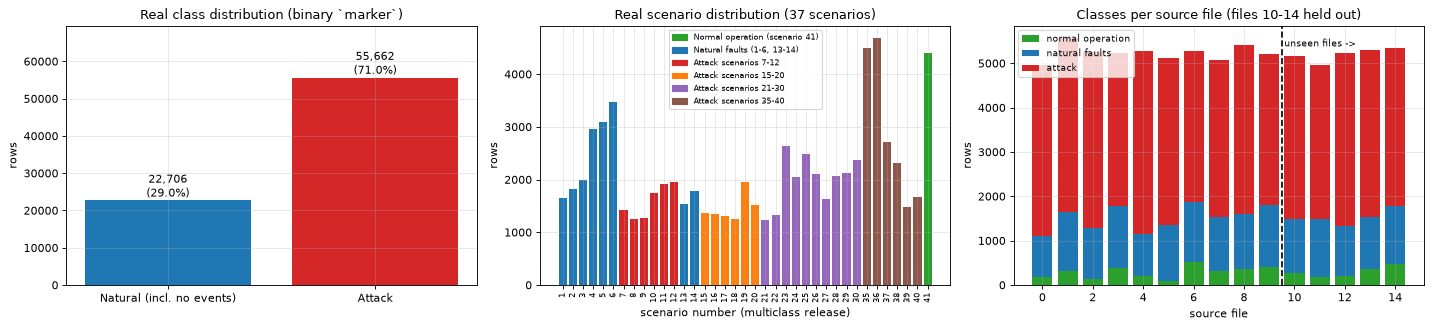

In [7]:
print("X (all rows after de-duplication):", X_all.shape, "| binary label vector:", attack_all.shape, "| source files:", len(fnames))
print(f"\n{len(FEAT)} feature names. First 12:", FEAT[:12])
print("last 12:", FEAT[-12:])
grp = pd.Series(FEAT).str.extract(r"^(R\d+|control_panel|snort)", expand=False).fillna("other").value_counts()
print("feature groups (prefix -> number of columns):", grp.to_dict())
print("\noriginal binary labels (raw, before de-duplication):", RAW_COUNTS)
print("original scenario numbers (multiclass release), rows after de-duplication:")
print(pd.Series(scen_all).value_counts().sort_index().to_dict())
print("\nmain task (0 = no event, 1 = attack):", {int(k): int(v) for k, v in zip(*np.unique(y_main[main_mask], return_counts=True))},
      "| natural-fault rows excluded from training:", int(is_natural.sum()))
print("training sample:", {int(k): int(v) for k, v in zip(*np.unique(y_main[TRAIN_IDX], return_counts=True))},
      "| row test:", {int(k): int(v) for k, v in zip(*np.unique(sets['row'][1], return_counts=True))},
      "| file test:", {int(k): int(v) for k, v in zip(*np.unique(sets['file'][1], return_counts=True))},
      "| natural-fault test (0 = natural fault, 1 = attack):", {int(k): int(v) for k, v in zip(*np.unique(sets['nat'][1], return_counts=True))})
print("per-agent class counts (first 3 agents):", [{int(k): int(v) for k, v in zip(*np.unique(y_main[agent_idx[a]], return_counts=True))} for a in range(3)])

GROUPS = [("Normal operation (scenario 41)", [41], "tab:green"), ("Natural faults (1-6, 13-14)", NATURAL_IDS, "tab:blue"),
          ("Attack scenarios 7-12", list(range(7, 13)), "tab:red"), ("Attack scenarios 15-20", list(range(15, 21)), "tab:orange"),
          ("Attack scenarios 21-30", list(range(21, 31)), "tab:purple"), ("Attack scenarios 35-40", list(range(35, 41)), "tab:brown")]
col_of = {s: c for _, ids, c in GROUPS for s in ids}
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
cnt = [int((~attack_all).sum()), int(attack_all.sum())]
bars = ax[0].bar(["Natural (incl. no events)", "Attack"], cnt, color=["tab:blue", "tab:red"])
for b_, c_ in zip(bars, cnt):
    ax[0].text(b_.get_x() + b_.get_width() / 2, c_, f"{c_:,}\n({c_ / sum(cnt):.1%})", ha="center", va="bottom")
ax[0].set_ylim(0, max(cnt) * 1.25); ax[0].set_ylabel("rows"); ax[0].set_title("Real class distribution (binary `marker`)")
sv, sc_ = np.unique(scen_all, return_counts=True)
ax[1].bar([str(s) for s in sv], sc_, color=[col_of[s] for s in sv])
for name_, _, c_ in GROUPS:
    pass
ax[1].legend(handles=[matplotlib.patches.Patch(color=c_, label=name_) for name_, _, c_ in GROUPS], fontsize=7); ax[1].set_xlabel("scenario number (multiclass release)"); ax[1].tick_params(axis="x", labelsize=7, rotation=90)
ax[1].set_ylabel("rows"); ax[1].set_title("Real scenario distribution (37 scenarios)")
files_ = np.arange(len(fnames))
b0 = np.array([((gid_all == i) & is_noev).sum() for i in files_]); b1 = np.array([((gid_all == i) & is_natural).sum() for i in files_]); b2 = np.array([((gid_all == i) & attack_all).sum() for i in files_])
ax[2].bar(files_, b0, color="tab:green", label="normal operation"); ax[2].bar(files_, b1, bottom=b0, color="tab:blue", label="natural faults"); ax[2].bar(files_, b2, bottom=b0 + b1, color="tab:red", label="attack")
ax[2].axvline(N_TRAIN_FILES - 0.5, color="k", ls="--"); ax[2].text(N_TRAIN_FILES - 0.4, ax[2].get_ylim()[1] * 0.92, "unseen files ->", fontsize=8)
ax[2].set_xlabel("source file"); ax[2].set_ylabel("rows"); ax[2].set_title("Classes per source file (files 10-14 held out)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

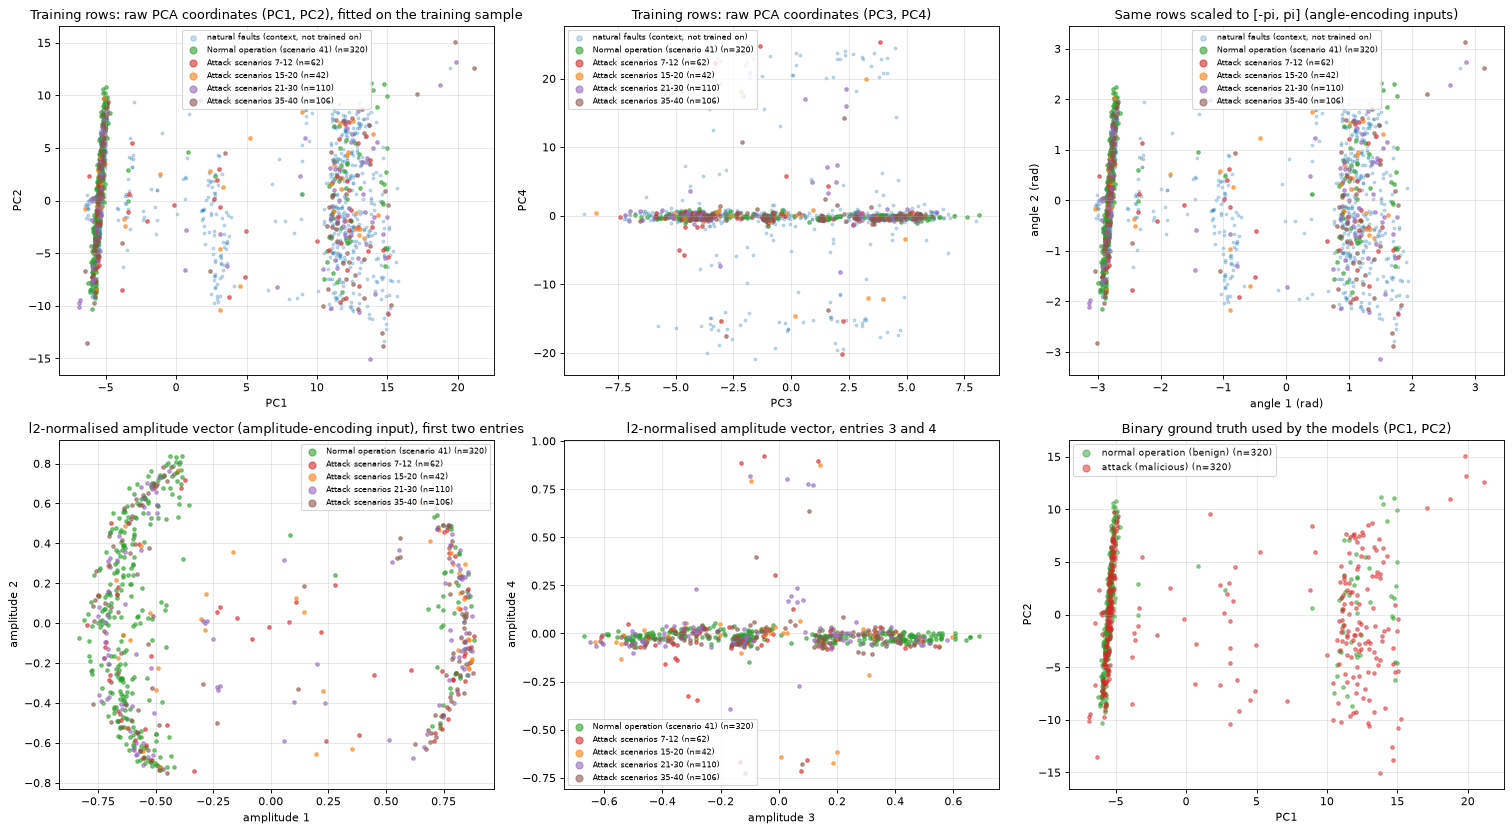

PCA(20) explained variance ratio, first 6: [0.375 0.154 0.071 0.056 0.046 0.044] | first two: 0.529 | total: 0.929
Reading: normal operation and attacks overlap in the first two components and separate partly along further components; the L2 normalisation of the amplitude encoding removes the vector length, which is larger for attacks: mean ||PCA vector|| normal 10.4 vs attack 13.5.


In [8]:
# Scatter plots of the REAL training observations, coloured by their ground-truth label (attacks by scenario family).
Ztr_ = Z["train"]; scen_tr = scen_all[TRAIN_IDX]; ytr_ = y_main[TRAIN_IDX]
A_tr_ = np.clip(ang_scaler.transform(Ztr_), -np.pi, np.pi)
amp_tr_ = np.zeros((len(Ztr_), 256)); amp_tr_[:, :D_FEAT] = Ztr_; amp_tr_ /= np.linalg.norm(amp_tr_, axis=1, keepdims=True)
nat_ctx = rng_global.choice(np.where(is_natural & tr_files)[0], 800, replace=False)           # natural faults: context only, never trained on
Zn_ = to_pca(nat_ctx)
fig, ax = plt.subplots(2, 3, figsize=(19, 10.5))
def draw(a, M, Mn, xl, yl, ttl):
    if Mn is not None:
        a.scatter(Mn[:, 0], Mn[:, 1], s=6, alpha=0.25, c="tab:blue", label="natural faults (context, not trained on)")
    for name_, ids, c in GROUPS:
        if ids == NATURAL_IDS:
            continue                                  # natural faults are context only (never in the training sample)
        msk = np.isin(scen_tr, ids)
        a.scatter(M[msk, 0], M[msk, 1], s=10, alpha=0.6, c=c, label=f"{name_} (n={msk.sum()})")
    a.set_xlabel(xl); a.set_ylabel(yl); a.set_title(ttl); a.legend(markerscale=2, fontsize=7)
draw(ax[0, 0], Ztr_[:, :2], Zn_[:, :2], "PC1", "PC2", "Training rows: raw PCA coordinates (PC1, PC2), fitted on the training sample")
draw(ax[0, 1], Ztr_[:, 2:4], Zn_[:, 2:4], "PC3", "PC4", "Training rows: raw PCA coordinates (PC3, PC4)")
draw(ax[0, 2], A_tr_[:, :2], np.clip(ang_scaler.transform(Zn_), -np.pi, np.pi)[:, :2], "angle 1 (rad)", "angle 2 (rad)", "Same rows scaled to [-pi, pi] (angle-encoding inputs)")
draw(ax[1, 0], amp_tr_[:, :2], None, "amplitude 1", "amplitude 2", "l2-normalised amplitude vector (amplitude-encoding input), first two entries")
draw(ax[1, 1], amp_tr_[:, 2:4], None, "amplitude 3", "amplitude 4", "l2-normalised amplitude vector, entries 3 and 4")
for lab, nm, c in ((0, "normal operation (benign)", "tab:green"), (1, "attack (malicious)", "tab:red")):
    msk = ytr_ == lab
    ax[1, 2].scatter(Ztr_[msk, 0], Ztr_[msk, 1], s=10, alpha=0.5, c=c, label=f"{nm} (n={msk.sum()})")
ax[1, 2].set_title("Binary ground truth used by the models (PC1, PC2)"); ax[1, 2].set_xlabel("PC1"); ax[1, 2].set_ylabel("PC2"); ax[1, 2].legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.show()
ev_ = pca.explained_variance_ratio_
print("PCA(20) explained variance ratio, first 6:", np.round(ev_[:6], 3), "| first two:", round(float(ev_[:2].sum()), 3), "| total:", round(float(ev_.sum()), 3))
print("Reading: normal operation and attacks overlap in the first two components and separate partly along further components; the L2 normalisation of the amplitude encoding removes the vector length, which is larger for attacks:",
      f"mean ||PCA vector|| normal {np.linalg.norm(Ztr_[ytr_ == 0], axis=1).mean():.1f} vs attack {np.linalg.norm(Ztr_[ytr_ == 1], axis=1).mean():.1f}.")

## 5. The quantum client: an exact batched simulator

The paper trains with Qiskit Aer's statevector simulator. Training here means 10 agents x 5 epochs x several mini-batches x 30 rounds x many runs; with the usual one-circuit-per-sample-per-parameter-shift recipe that is hundreds of millions of circuit evaluations (the paper itself needs 100,000 samples and 100 rounds). We therefore use a small **exact NumPy statevector simulator** that is written for this circuit and checked against PennyLane (section 7):

* The circuit is $U_{enc}(x)$ followed by $L$ identical-in-structure layers: per qubit $R_z(\theta_z)R_y(\theta_y)R_x(\theta_x)$, then the CNOT chain CNOT(0,1), CNOT(1,2), ..., CNOT(6,7). The 8 single-qubit unitaries of a layer are fused into two $16\times16$ Kronecker blocks (qubits 0-3 and 4-7); the CNOT chain is a fixed permutation of the 256 basis states (each qubit becomes the parity of itself and all qubits before it).
* The output is $\langle Z_r\rangle$ on one qubit $r$. The gradient of the loss $\sum_j w_j f_j$ with respect to all 240 angles comes from the **adjoint method** (one forward and one backward sweep, exactly the quantity that the parameter-shift rule would give with 480 circuit runs per sample). The cotangent state at the input also gives the gradient with respect to the *input features*, which the FGSM attack needs.
* All agents are simulated **at once** (a leading "agent" axis), each with its own parameters.
* Amplitude encoding: the 20 features are zero-padded to 256 amplitudes and $\ell_2$-normalised; angle encoding: the three rotation chunks listed in the table above, all acting before the ansatz, so the encoded state is a product state.

In [9]:
import numpy as np

DIM = 2 ** N_QUBITS      # N_QUBITS comes from the configuration cell
DT = np.complex64


def prefix_xor_perm(n=N_QUBITS):
    """CNOT(0,1), CNOT(1,2), ..., CNOT(n-2,n-1) applied in this order = prefix-XOR of the basis-state bits (qubit 0 = MSB)."""
    idx = np.arange(2 ** n)
    out = np.empty_like(idx)
    for i in idx:
        bits = [(i >> (n - 1 - j)) & 1 for j in range(n)]
        for j in range(1, n):
            bits[j] ^= bits[j - 1]
        out[i] = sum(b << (n - 1 - j) for j, b in enumerate(bits))
    return out            # new_state[out[i]] = old_state[i]


PM = prefix_xor_perm()
INV_PM = np.argsort(PM)     # new_state = old_state[INV_PM]


def rot_mats(theta):
    """theta (..., 3) = (theta_x, theta_y, theta_z) -> U = Rz Ry Rx (Rx acts first) and dU/d(theta_x,y,z), shapes (...,2,2) and (...,3,2,2)."""
    a, b, c = theta[..., 0], theta[..., 1], theta[..., 2]
    ca, sa = np.cos(a / 2), np.sin(a / 2)
    cb, sb = np.cos(b / 2), np.sin(b / 2)
    shp = theta.shape[:-1]
    Rx = np.zeros(shp + (2, 2), np.complex128); Ry = np.zeros_like(Rx); Rz = np.zeros_like(Rx)
    Rx[..., 0, 0] = ca; Rx[..., 1, 1] = ca; Rx[..., 0, 1] = -1j * sa; Rx[..., 1, 0] = -1j * sa
    Ry[..., 0, 0] = cb; Ry[..., 1, 1] = cb; Ry[..., 0, 1] = -sb; Ry[..., 1, 0] = sb
    Rz[..., 0, 0] = np.exp(-0.5j * c); Rz[..., 1, 1] = np.exp(0.5j * c)
    X = np.array([[0, 1], [1, 0]], np.complex128); Y = np.array([[0, -1j], [1j, 0]]); Z = np.array([[1, 0], [0, -1]], np.complex128)
    U = Rz @ Ry @ Rx
    dX = -0.5j * (Rz @ Ry @ X @ Rx)
    dY = -0.5j * (Rz @ Y @ Ry @ Rx)
    dZ = -0.5j * (Z @ U)
    return U, np.stack([dX, dY, dZ], axis=-3)


def kron4(U):
    """U (C,L,4,2,2) -> kron(U0,U1,U2,U3) as (C,L,16,16), qubit 0 = most significant bit."""
    A = np.einsum("zlab,zlcd,zlef,zlgh->zlacegbdfh", U[:, :, 0], U[:, :, 1], U[:, :, 2], U[:, :, 3], optimize=True)
    return A.reshape(U.shape[0], U.shape[1], 16, 16)


def half_grads(G, U):
    """G (C,L,16,16) = dL/dA-style matrix of a 4-qubit kron gate, U (C,L,4,2,2) -> (C,L,4,2,2): G_q[s,t] with other factors contracted."""
    T = G.reshape(G.shape[:2] + (2,) * 8)
    outs = []
    subs = ["zlabcdefgh"]
    for q in range(4):
        # indices: rows a,b,c,d  cols e,f,g,h ; qubit q keeps (row_q, col_q)
        rows, cols = "abcd", "efgh"
        ops = ["zl" + rows + cols]
        args = [T]
        for r in range(4):
            if r != q:
                ops.append("zl" + rows[r] + cols[r]); args.append(U[:, :, r])
        outs.append(np.einsum(",".join(ops) + "->zl" + rows[q] + cols[q], *args, optimize=True))
    return np.stack(outs, axis=2)


def _apply_layers(S, Ahi, Alo, l):
    hi = np.matmul(Ahi[:, l, None], S)
    lo = np.matmul(hi, np.swapaxes(Alo[:, l, None], -1, -2))
    return hi, lo


def q_forward(theta, S0, readout, store=False):
    """theta (C,L,n,3); S0 (C,B,2^n) complex input states. Returns f (C,B) = <Z_readout>, final state, cache."""
    C, L, n, _ = theta.shape
    B = S0.shape[1]
    U, dU = rot_mats(theta.astype(np.float64))
    U = U.astype(DT)
    Ahi, Alo = kron4(U[:, :, 0:4]), kron4(U[:, :, 4:8])
    S = S0.astype(DT).reshape(C, B, 16, 16)
    cache = []
    for l in range(L):
        hi, lo = _apply_layers(S, Ahi, Alo, l)
        if store:
            cache.append((S, hi))
        S = lo.reshape(C, B, DIM)[..., INV_PM].reshape(C, B, 16, 16)
    S = S.reshape(C, B, DIM)
    p = S.real ** 2 + S.imag ** 2
    sign = 1 - 2 * ((np.arange(DIM) >> (n - 1 - readout)) & 1)
    f = (p * sign).sum(-1)
    return f, S, (U, dU, Ahi, Alo, cache, sign)


def q_grad(theta, S0, readout, w):
    """Gradient of sum_{c,b} w[c,b] f[c,b] w.r.t. theta (C,L,n,3) and the real input amplitudes (C,B,2^n). Returns f, g_theta, g_in."""
    C, L, n, _ = theta.shape
    B = S0.shape[1]
    f, S, (U, dU, Ahi, Alo, cache, sign) = q_forward(theta, S0, readout, store=True)
    if callable(w):
        w = w(f)                                                      # weights may depend on the forward values (e.g. dBCE/df)
    lam = (w[..., None] * sign * S).astype(DT)
    Ghi = np.empty((C, L, 16, 16), DT); Glo = np.empty((C, L, 16, 16), DT)
    for l in range(L - 1, -1, -1):
        lam = lam.reshape(C, B, DIM)[..., PM].reshape(C, B, 16, 16)    # P^dagger lambda
        psi_in, psi_mid = cache[l]
        # lo gate: psi_lo = psi_mid @ Alo^T ;  G_lo[o,i] = sum_{b,h} conj(lam[b,h,o]) psi_mid[b,h,i]
        Glo[:, l] = np.matmul(np.swapaxes(lam.conj(), -1, -2), psi_mid).sum(1)
        lam = np.matmul(lam, Alo[:, l, None].conj())                  # lam_mid = lam @ conj(Alo)
        # hi gate: psi_hi = Ahi @ psi_in ; G_hi[o,i] = sum_{b,l} conj(lam_mid[b,o,l]) psi_in[b,i,l]
        Ghi[:, l] = np.matmul(lam.conj(), np.swapaxes(psi_in, -1, -2)).sum(1)
        lam = np.matmul(np.swapaxes(Ahi[:, l, None].conj(), -1, -2), lam)
    lam_in = lam.reshape(C, B, DIM)                                   # complex cotangent at the input state: M psi (weighted)
    g_in = 2 * np.real(lam_in)
    Uc = U.astype(np.complex128)
    Gq = np.concatenate([half_grads(Ghi.astype(np.complex128), Uc[:, :, 0:4]),
                         half_grads(Glo.astype(np.complex128), Uc[:, :, 4:8])], axis=2)    # (C,L,8,2,2)
    g = 2 * np.real(np.einsum("zlqjst,zlqst->zlqj", dU, Gq))
    return f, g, lam_in


def amp_state(X, dtype=DT):
    """X (..., d) real features -> (..., 2^n) amplitudes: zero padded and L2 normalised."""
    d = X.shape[-1]
    out = np.zeros(X.shape[:-1] + (DIM,), np.float64)
    out[..., :d] = X
    nrm = np.linalg.norm(out, axis=-1, keepdims=True)
    out = out / np.maximum(nrm, 1e-12)
    return out.astype(dtype)


def angle_state(X, n=N_QUBITS, dtype=DT):
    """X (..., 20) angles -> product state. chunk0: RY(x_q) on qubits 0..7; chunk1: RX(x_{8+q}) on qubits 0..7; chunk2: RY(x_{16+q}) on qubits 0..3."""
    sh = X.shape[:-1]
    v = np.zeros(sh + (n, 2), np.complex128)
    c, s = np.cos(X[..., :8] / 2), np.sin(X[..., :8] / 2)
    v[..., 0], v[..., 1] = c, s
    b = X[..., 8:16]
    cb, sb = np.cos(b / 2), np.sin(b / 2)
    v0 = cb * v[..., 0] - 1j * sb * v[..., 1]; v1 = -1j * sb * v[..., 0] + cb * v[..., 1]
    v[..., 0], v[..., 1] = v0, v1
    cc = np.cos(X[..., 16:20] / 2); sc = np.sin(X[..., 16:20] / 2)
    v0 = cc * v[..., :4, 0] - sc * v[..., :4, 1]; v1 = sc * v[..., :4, 0] + cc * v[..., :4, 1]
    v[..., :4, 0], v[..., :4, 1] = v0, v1
    psi = np.ones(sh + (1,), np.complex128)
    for q in range(n):
        psi = (psi[..., :, None] * v[..., q, None, :]).reshape(sh + (-1,))
    return psi.astype(dtype)

In [10]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def bce(f, y):
    p = np.clip(sigmoid(f), 1e-7, 1 - 1e-7)
    return float(np.mean(-(y * np.log(p) + (1 - y) * np.log(1 - p))))

def trimmed_mean(U, t):
    """coordinate-wise trimmed mean over axis 0: drops the t smallest and t largest values of every coordinate (paper Eq. 23)."""
    if t <= 0:
        return U.mean(0)
    S = np.sort(U, axis=0)
    return S[t:U.shape[0] - t].mean(0)

class Adam:
    def __init__(self, shape, lr, b1=0.9, b2=0.999, eps=1e-8):
        self.m = np.zeros(shape); self.v = np.zeros(shape); self.t = 0
        self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps
    def step(self, g):
        self.t += 1
        self.m = self.b1 * self.m + (1 - self.b1) * g
        self.v = self.b2 * self.v + (1 - self.b2) * g * g
        mh = self.m / (1 - self.b1 ** self.t); vh = self.v / (1 - self.b2 ** self.t)
        return -self.lr * mh / (np.sqrt(vh) + self.eps)

def q_scores(theta, S, readout, bs=1500):
    """<Z_readout> of a single parameter set for a batch of encoded states S (N, 256)."""
    return np.concatenate([q_forward(theta[None], S[None, i:i + bs], readout)[0][0] for i in range(0, len(S), bs)])

def local_epochs(thetas, S, y, readout, E, B, lr, rng):
    """E epochs of ADAM mini-batch training for all agents at once. thetas (C,L,8,3); S (C,n,256); y (C,n)."""
    C, n = y.shape
    th = thetas.copy()
    opt = Adam(th.shape, lr)
    for e in range(E):
        perm = np.argsort(rng.random((C, n)), axis=1)
        for s in range(0, n - B + 1, B):
            idx = perm[:, s:s + B]
            Sb = np.take_along_axis(S, idx[:, :, None], axis=1)
            yb = np.take_along_axis(y, idx, axis=1)
            f, g, _ = q_grad(th, Sb, readout, lambda f, yb=yb: (sigmoid(f) - yb) / B)     # dBCE/df, averaged over the batch
            th = th + opt.step(g)
    return th

def quantum_fl(S_tr, y_tr, ev_S, ev_y, *, readout, L, rounds, E=None, B=None, lr=None, init_scale=None, mode="fed", agg="trimmed",
               t_trim=None, byz=(), byz_gain=None, dp_sigma=0.0, dp_clip=None, seed=0, probe=None, eval_every=1):
    """Federated (mode 'fed') or isolated (mode 'local') training of the VQC.  S_tr (C,n,256) encoded states of the C agents.
    With C = 1 and agg 'mean' this is plain centralised training.  Returns dict(theta, curve, local_final, thetas)."""
    E = LOCAL_EPOCHS if E is None else E; B = BATCH if B is None else B; lr = LR if lr is None else lr
    init_scale = INIT_SCALE if init_scale is None else init_scale; t_trim = TRIM_T if t_trim is None else t_trim
    byz_gain = BYZ_GAIN if byz_gain is None else byz_gain
    rng = np.random.default_rng(seed)
    C, n = y_tr.shape
    theta = rng.normal(0.0, init_scale, (L, N_QUBITS, 3))
    thetas = np.repeat(theta[None], C, 0)
    curve = []
    t0 = time.time()
    for r in range(1, rounds + 1):
        start = np.repeat(theta[None], C, 0) if mode == "fed" else thetas
        new = local_epochs(start, S_tr, y_tr, readout, E, B, lr, rng)
        if mode == "fed":
            d = new - theta[None]                                   # what each agent would send
            for i in byz:
                d[i] = -byz_gain * d[i]                             # CHOICE: Byzantine agents send a sign-flipped, amplified update
            if dp_clip is not None:
                d = np.clip(d, -dp_clip, dp_clip)
            if dp_sigma > 0:
                d = d + rng.laplace(0.0, dp_sigma, d.shape)         # paper Eq. 20 / 25: Laplace noise on the update
            theta = theta + (trimmed_mean(d, t_trim) if agg == "trimmed" else d.mean(0))
        else:
            thetas = new
        rec = dict(round=r)
        if mode != "fed" and r % eval_every and r != rounds:
            continue
        if mode == "fed":
            f = q_scores(theta, ev_S, readout)
            rec["acc"] = float(np.mean((f > 0) == ev_y)); rec["loss"] = bce(f, ev_y)
            if probe is not None:
                rec["train_loss"] = bce(q_scores(theta, probe[0], readout), probe[1])
        else:
            fs = q_forward(thetas, np.repeat(ev_S[None], C, 0), readout)[0]
            accs = [float(np.mean((fs[c] > 0) == ev_y)) for c in range(C)]
            rec["acc"] = float(np.mean(accs)); rec["loss"] = float(np.mean([bce(fs[c], ev_y) for c in range(C)]))
        rec["time"] = time.time() - t0
        curve.append(rec)
    return dict(theta=theta, thetas=thetas, local_final=new, curve=pd.DataFrame(curve))

# ---------------- classical federated baselines on the same inputs: tiny MLP 20-16-1 (353 parameters) ----------------
H_MLP = 16
N_MLP = D_FEAT * H_MLP + H_MLP + H_MLP + 1

def mlp_unpack(w):
    W1 = w[:D_FEAT * H_MLP].reshape(D_FEAT, H_MLP); b1 = w[D_FEAT * H_MLP:D_FEAT * H_MLP + H_MLP]
    W2 = w[D_FEAT * H_MLP + H_MLP:D_FEAT * H_MLP + 2 * H_MLP]; b2 = w[-1]
    return W1, b1, W2, b2

def mlp_logit(w, X):
    W1, b1, W2, b2 = mlp_unpack(w)
    return np.tanh(X @ W1 + b1) @ W2 + b2

def mlp_grad(w, X, y):
    """mean-BCE gradient w.r.t. the weights, and the per-sample dBCE/dx (for FGSM)."""
    W1, b1, W2, b2 = mlp_unpack(w)
    h = np.tanh(X @ W1 + b1); z = h @ W2 + b2
    d = (sigmoid(z) - y) / len(y)
    dh = np.outer(d, W2) * (1 - h ** 2)
    g = np.concatenate([(X.T @ dh).ravel(), dh.sum(0), h.T @ d, [d.sum()]])
    return g, (dh @ W1.T) * len(y)

def mlp_local(w0, X, y, E, B, lr, rng, mu=0.0, c_glob=None, c_loc=None):
    w = w0.copy(); n = len(y); steps = 0
    for e in range(E):
        perm = rng.permutation(n)
        for s in range(0, n - B + 1, B):
            idx = perm[s:s + B]
            g, _ = mlp_grad(w, X[idx], y[idx])
            if mu > 0: g = g + mu * (w - w0)                        # FedProx proximal term
            if c_glob is not None: g = g - c_loc + c_glob           # SCAFFOLD drift correction
            w = w - lr * g; steps += 1
    return w, steps

def classical_fl(X_tr, y_tr, ev_X, ev_y, *, algo="fedavg", rounds, E=None, B=None, lr=0.05, mu=0.1, agg="mean", t_trim=None, byz=(),
                 byz_gain=None, dp_sigma=0.0, dp_clip=None, seed=0):
    """algo: 'fedavg' | 'fedprox' | 'scaffold'.  X_tr (C,n,20) standardised PCA features."""
    E = LOCAL_EPOCHS if E is None else E; B = BATCH if B is None else B
    t_trim = TRIM_T if t_trim is None else t_trim; byz_gain = BYZ_GAIN if byz_gain is None else byz_gain
    rng = np.random.default_rng(seed)
    C, n = y_tr.shape
    w = np.concatenate([rng.normal(0, 1 / np.sqrt(D_FEAT), D_FEAT * H_MLP), np.zeros(H_MLP), rng.normal(0, 1 / np.sqrt(H_MLP), H_MLP), [0.0]])
    c_glob = np.zeros(N_MLP); c_loc = np.zeros((C, N_MLP))
    curve = []
    for r in range(1, rounds + 1):
        D_, dcs = [], []
        for i in range(C):
            if algo == "scaffold":
                wi, K = mlp_local(w, X_tr[i], y_tr[i], E, B, lr, rng, c_glob=c_glob, c_loc=c_loc[i])
                c_new = c_loc[i] - c_glob + (w - wi) / (K * lr)
                dcs.append(c_new - c_loc[i]); c_loc[i] = c_new
            else:
                wi, _ = mlp_local(w, X_tr[i], y_tr[i], E, B, lr, rng, mu=mu if algo == "fedprox" else 0.0)
            d = wi - w
            if i in byz: d = -byz_gain * d
            D_.append(d)
        D_ = np.array(D_)
        if dp_clip is not None: D_ = np.clip(D_, -dp_clip, dp_clip)
        if dp_sigma > 0: D_ = D_ + rng.laplace(0.0, dp_sigma, D_.shape)
        w = w + (trimmed_mean(D_, t_trim) if agg == "trimmed" else D_.mean(0))
        if algo == "scaffold": c_glob = c_glob + np.mean(dcs, axis=0)
        f = mlp_logit(w, ev_X)
        curve.append(dict(round=r, acc=float(np.mean((f > 0) == ev_y)), loss=bce(f, ev_y)))
    return dict(w=w, curve=pd.DataFrame(curve))

# ---------------- metrics and the FGSM-style input attack ----------------
def metrics(scores, y):
    """scores: > 0 means attack.  Attack is the positive class (paper Eq. 26-28)."""
    pred = (scores > 0).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    acc = (tp + tn) / len(y)
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-12)
    try:
        auc = float(roc_auc_score(y, scores))
    except ValueError:
        auc = float("nan")
    return dict(ACC=acc, Precision=prec, Recall=rec, F1=f1, AUC=auc, FPR=fp / max(fp + tn, 1), FNR=fn / max(fn + tp, 1), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def quantum_input_grad(theta, Zraw, y, enc_fn, readout, bs=800):
    """per-sample gradient of the BCE loss w.r.t. the 20 PCA features: adjoint pass for the circuit, finite differences only for the
    (cheap, circuit-free) encoder."""
    out = []
    for i in range(0, len(Zraw), bs):
        Zb, yb = Zraw[i:i + bs], y[i:i + bs]
        S = enc_fn(Zb)
        f, _, lam = q_grad(theta[None], S[None], readout, lambda f: sigmoid(f) - yb[None])      # w_i = dBCE_i/df_i (not averaged)
        lam = lam[0].astype(np.complex128)
        g = np.zeros_like(Zb)
        for k in range(Zb.shape[1]):
            h = 1e-3 * SIGMA[k]
            Zp = Zb.copy(); Zp[:, k] += h; Zm = Zb.copy(); Zm[:, k] -= h
            dpsi = (enc_fn(Zp, dtype=np.complex128) - enc_fn(Zm, dtype=np.complex128)) / (2 * h)
            g[:, k] = 2 * np.real(np.sum(np.conj(lam) * dpsi, axis=1))
        out.append(g)
    return np.concatenate(out)

def fgsm(Zraw, grad, eps):
    """x_adv = x + eps * sigma_k * sign(dL/dx_k)   (l_inf-bounded, FGSM-style, paper Sec. 3.3)."""
    return Zraw + eps * SIGMA * np.sign(grad)

Encoders and the encoded data. `ENC[...]` maps PCA features to input states; the states of all agents and test sets are computed once.

In [11]:
def enc_amp(Zx, dtype=DT):
    return amp_state(Zx, dtype=dtype)                                                      # zero-padded, l2-normalised amplitudes

def enc_ang(Zx, dtype=DT):
    return angle_state(np.clip(ang_scaler.transform(Zx), -np.pi, np.pi), dtype=dtype)      # angles in [-pi, pi], test values clipped

ENC = {"amplitude": enc_amp, "angle": enc_ang}
STATES = {}
for _name, _fn in ENC.items():
    STATES[_name] = dict(
        agents=np.stack([_fn(Z["agents"][a]) for a in range(MAX_AGENTS)]),                  # (agents, n_i, 256)
        sets={k: _fn(Z[k]) for k in sets},
        probe=_fn(Z["train"][np.random.default_rng(SEED).choice(len(Z["train"]), min(320, len(Z["train"])), replace=False)]))
Y_AGENTS = np.stack([y_main[agent_idx[a]] for a in range(MAX_AGENTS)])                      # (agents, n_i)
Y_SET = {k: v[1] for k, v in sets.items()}
Y_PROBE = y_main[TRAIN_IDX][np.random.default_rng(SEED).choice(len(TRAIN_IDX), min(320, len(TRAIN_IDX)), replace=False)]
print({k: v.shape for k, v in STATES["amplitude"].items() if hasattr(v, "shape")}, "| sets:", {k: v.shape for k, v in STATES["amplitude"]["sets"].items()})

{'agents': (10, 64, 256), 'probe': (320, 256)} | sets: {'val': (600, 256), 'row': (600, 256), 'file': (600, 256), 'nat': (600, 256)}


## 6. Design check on the validation split: which qubit to measure

The paper writes "a measurement observable $O$" without saying where. With a CNOT chain 0 -> 1 -> ... -> 7, information about the input flows towards high qubit numbers, so qubit 7 is the natural candidate, but qubit 0 (which the other notebooks of this repository use) and the middle qubit 3 are cheap to test. We train the amplitude-encoded VQC centrally on the training sample for `DESIGN_STEPS` ADAM steps (learning rate 0.03, batch 96) for each candidate and keep the one with the best accuracy on the **validation** split; the test sets are not touched.

In [12]:
def central_design(readout, steps, seed=0, lr=0.03, B=96, L=N_LAYERS):
    r = np.random.default_rng(seed)
    S = STATES["amplitude"]["agents"][:N_AGENTS].reshape(1, -1, DIM); y = Y_AGENTS[:N_AGENTS].reshape(1, -1)
    th = r.normal(0, INIT_SCALE, (1, L, N_QUBITS, 3)); opt = Adam(th.shape, lr)
    for s in range(steps):
        idx = r.choice(y.shape[1], B, replace=False)
        yb = y[:, idx]
        f, g, _ = q_grad(th, S[:, idx], readout, lambda f: (sigmoid(f) - yb) / B)
        th = th + opt.step(g)
    fv = q_scores(th[0], STATES["amplitude"]["sets"]["val"], readout)
    return float(np.mean((fv > 0) == Y_SET["val"]))

t0 = time.time()
design = {r_: central_design(r_, DESIGN_STEPS) for r_ in (0, 3, 7)}
READOUT = max(design, key=design.get)
print("validation accuracy by measured qubit:", {k: round(v, 3) for k, v in design.items()}, "-> measured qubit", READOUT, f"({time.time() - t0:.0f} s)")

validation accuracy by measured qubit: {0: 0.642, 3: 0.667, 7: 0.663} -> measured qubit 3 (26 s)


## 7. Quantum Circuit Architecture

The model of the paper has two variants that differ only in the data-encoding block $U_{enc}(x)$, so two architectures are drawn, each from the **PennyLane QNode that the equivalence test below compares with the simulator**:

1. **Amplitude-encoded VQC** (the paper's main model): `AmplitudeEmbedding` of the 20 PCA features (zero-padded to 256 amplitudes, normalised) on 8 qubits; then 10 layers of $R_x, R_y, R_z$ on every qubit followed by the nearest-neighbour CNOT chain; measurement $\langle Z\rangle$ on the qubit chosen in section 6.
2. **Angle-encoded VQC** (ablation): $R_y(x_q)$ on qubits 0-7 (features 1-8), $R_x(x_{8+q})$ on qubits 0-7 (features 9-16), $R_y(x_{16+q})$ on qubits 0-3 (features 17-20), then the same ansatz.

**Assumptions where the paper is silent.** (i) The paper's Eq. 18 lists $R_z R_y R_x$ as an operator product, so $R_x$ acts first; this is what is drawn. (ii) "Nearest-neighbour CNOTs" is read as the open chain CNOT(0,1), ..., CNOT(6,7) in this order, without a closing CNOT(7,0). (iii) The amplitude encoding of 20 numbers fills only 20 of the 256 basis states, so qubits 0-2 are $|0\rangle$ before the ansatz acts; the paper says "$\lceil\log_2 d\rceil$ qubits" in Sec. 7.7 but also q = 8, so the three extra qubits are ansatz-only workspace. (iv) The state preparation is drawn as one `StatePrep` box (as PennyLane's `default.qubit` executes it); its gate-level cost (Möttönen decomposition into rotations and CNOTs) is reported separately because it dwarfs the ansatz depth. (v) The rotation angles shown in the drawings are the random initial values.

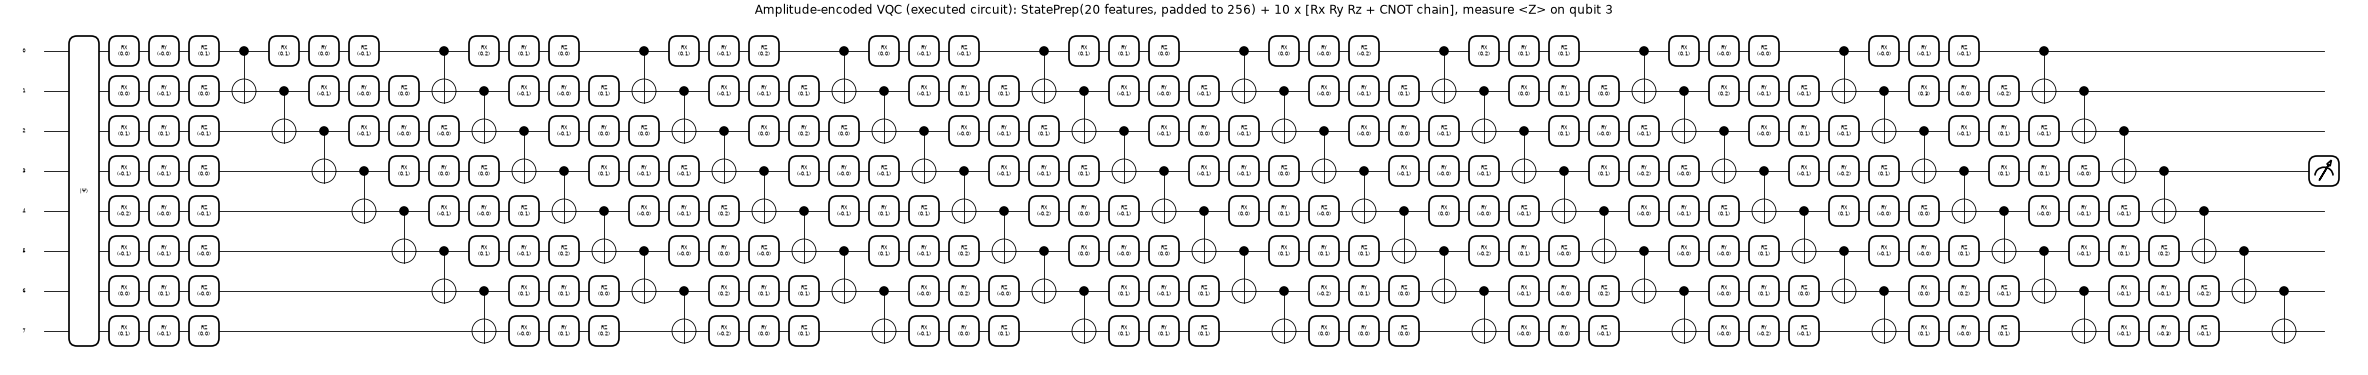

Amplitude-encoded VQC (StatePrep as one op): qubits=8, depth=56, gates=311, trainable circuit parameters=240 (= 10 layers x 8 qubits x 3), data-dependent angles=0


Amplitude-encoded VQC (Mottonen gate-level state preparation): qubits=8, depth=976, gates=1242, trainable circuit parameters=240 (= 10 layers x 8 qubits x 3), data-dependent angles=0


check: AmplitudeEmbedding and the gate-level Mottonen preparation give the same <Z> (0.725517); the state preparation alone costs far more depth than the 10-layer ansatz.


In [13]:
dev8 = qml.device("default.qubit", wires=N_QUBITS)

def make_qnode(encoding, L, readout, prep="embedding"):
    @qml.qnode(dev8, interface="autograd", diff_method="backprop")
    def circuit(x, theta):
        if encoding == "amplitude":
            if prep == "embedding":
                qml.AmplitudeEmbedding(x, wires=range(N_QUBITS), pad_with=0.0, normalize=True)
            else:                                                   # gate-level state preparation, only used to count resources
                v = np.zeros(2 ** N_QUBITS); v[:D_FEAT] = x; v = v / np.linalg.norm(v)
                qml.MottonenStatePreparation(v, wires=range(N_QUBITS))
        else:
            for q in range(8): qml.RY(x[q], wires=q)
            for q in range(8): qml.RX(x[8 + q], wires=q)
            for q in range(4): qml.RY(x[16 + q], wires=q)
        for l in range(L):
            for q in range(N_QUBITS):                               # Eq. 18: R_z R_y R_x on every qubit (R_x acts first)
                qml.RX(theta[l, q, 0], wires=q); qml.RY(theta[l, q, 1], wires=q); qml.RZ(theta[l, q, 2], wires=q)
            for q in range(N_QUBITS - 1):                           # nearest-neighbour entanglers
                qml.CNOT(wires=[q, q + 1])
        return qml.expval(qml.PauliZ(readout))
    return circuit

x_demo_amp = Z["train"][0]
x_demo_ang = np.clip(ang_scaler.transform(Z["train"][:1]), -np.pi, np.pi)[0]          # a real training row, as angles
th_demo = pnp.array(np.random.default_rng(0).normal(0, INIT_SCALE, (N_LAYERS, N_QUBITS, 3)), requires_grad=True)

def report(name, qn, x, th):
    sp = qml.specs(qn, level="device")(x, th)
    print(f"{name}: qubits={sp.num_device_wires}, depth={int(sp.resources.depth)}, gates={int(sp.resources.num_gates)}, trainable circuit parameters={th.size} (= {N_LAYERS} layers x {N_QUBITS} qubits x 3), data-dependent angles={0 if 'mplitude' in name else D_FEAT}")

qn_amp = make_qnode("amplitude", N_LAYERS, READOUT)
fig, ax = qml.draw_mpl(qn_amp, decimals=1, fontsize=9)(x_demo_amp, th_demo)
fig.set_dpi(40); fig.suptitle(f"Amplitude-encoded VQC (executed circuit): StatePrep(20 features, padded to 256) + {N_LAYERS} x [Rx Ry Rz + CNOT chain], measure <Z> on qubit {READOUT}", fontsize=22, y=1.02)
plt.show()
report("Amplitude-encoded VQC (StatePrep as one op)", qn_amp, x_demo_amp, th_demo)
qn_mot = make_qnode("amplitude", N_LAYERS, READOUT, prep="mottonen")
report("Amplitude-encoded VQC (Mottonen gate-level state preparation)", qn_mot, x_demo_amp, th_demo)
f_a = float(qn_amp(x_demo_amp, th_demo)); f_m = float(qn_mot(x_demo_amp, th_demo))
assert abs(f_a - f_m) < 1e-8, (f_a, f_m)
print(f"check: AmplitudeEmbedding and the gate-level Mottonen preparation give the same <Z> ({f_a:.6f}); the state preparation alone costs far more depth than the 10-layer ansatz.")

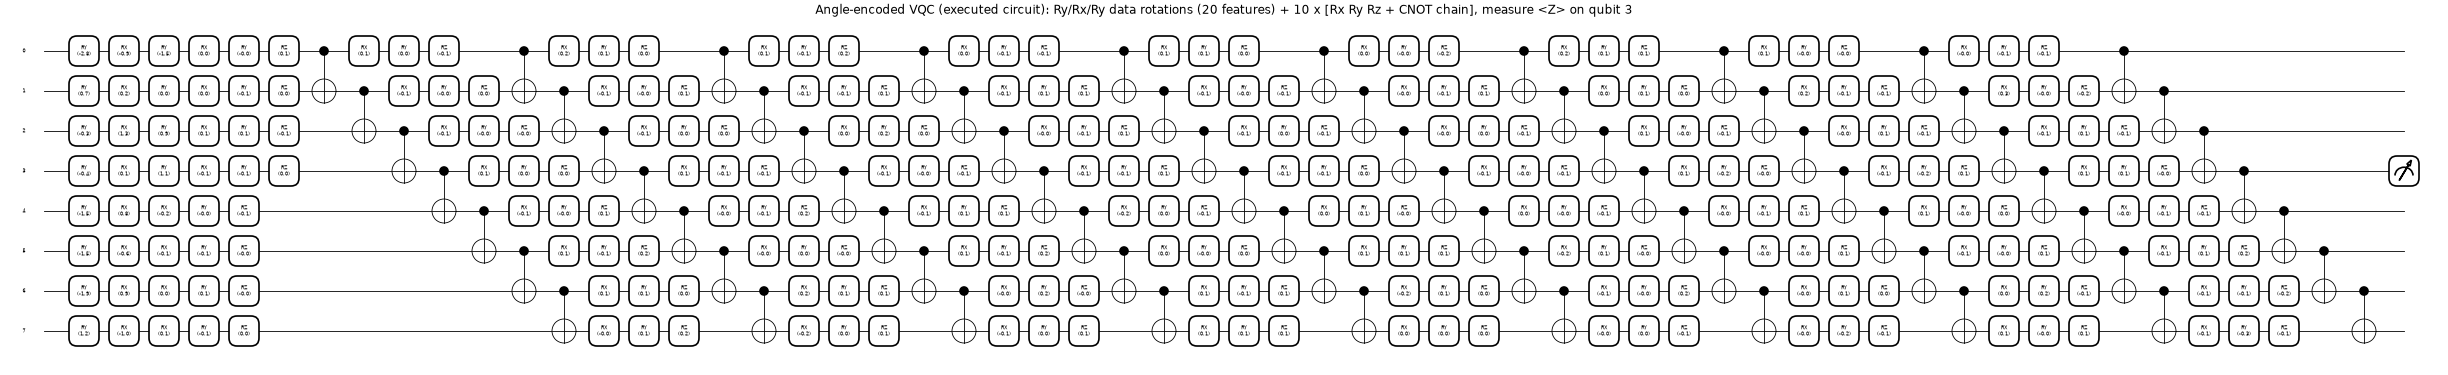

Angle-encoded VQC: qubits=8, depth=58, gates=330, trainable circuit parameters=240 (= 10 layers x 8 qubits x 3), data-dependent angles=20


In [14]:
qn_ang = make_qnode("angle", N_LAYERS, READOUT)
fig, ax = qml.draw_mpl(qn_ang, decimals=1, fontsize=9)(x_demo_ang, th_demo)
fig.set_dpi(40); fig.suptitle(f"Angle-encoded VQC (executed circuit): Ry/Rx/Ry data rotations (20 features) + {N_LAYERS} x [Rx Ry Rz + CNOT chain], measure <Z> on qubit {READOUT}", fontsize=22, y=1.02)
plt.show()
report("Angle-encoded VQC", qn_ang, x_demo_ang, th_demo)

In [15]:
# ---- equivalence test: the NumPy simulator used for training == the PennyLane QNodes that are drawn above (outputs and gradients) ----
chk_rng = np.random.default_rng(1)
n_chk = 4
for encoding, qn in (("amplitude", qn_amp), ("angle", qn_ang)):
    Zc = Z["train"][chk_rng.choice(len(Z["train"]), n_chk, replace=False)]
    Xc = Zc if encoding == "amplitude" else np.clip(ang_scaler.transform(Zc), -np.pi, np.pi)
    thc = chk_rng.normal(0, 0.8, (1, N_LAYERS, N_QUBITS, 3)); wc = chk_rng.normal(0, 1, (1, n_chk))
    S_in = amp_state(Zc)[None] if encoding == "amplitude" else angle_state(Xc)[None]
    f_sim, g_sim, _ = q_grad(thc, S_in, READOUT, wc)
    f_ref = np.array([float(qn(Xc[j], pnp.array(thc[0], requires_grad=False))) for j in range(n_chk)])
    loss = lambda t: sum(wc[0, j] * qn(pnp.array(Xc[j], requires_grad=False), t) for j in range(n_chk))
    g_ref = qml.grad(loss)(pnp.array(thc[0], requires_grad=True))
    assert np.allclose(f_sim[0], f_ref, atol=1e-5), (encoding, np.abs(f_sim[0] - f_ref).max())
    assert np.allclose(g_sim[0], g_ref, atol=1e-5), (encoding, np.abs(g_sim[0] - g_ref).max())
    print(f"{encoding}: max |<Z> simulator - QNode| = {np.abs(f_sim[0] - f_ref).max():.1e}, max |gradient simulator - autograd of QNode| = {np.abs(g_sim[0] - g_ref).max():.1e} (240 angles)")
print("assert passed: the simulator is the drawn circuit.")

amplitude: max |<Z> simulator - QNode| = 1.1e-07, max |gradient simulator - autograd of QNode| = 3.2e-07 (240 angles)


angle: max |<Z> simulator - QNode| = 2.9e-08, max |gradient simulator - autograd of QNode| = 1.4e-07 (240 angles)
assert passed: the simulator is the drawn circuit.


In [16]:
# ---- depth of the ansatz as a function of the number of layers (paper Fig. 5 / 18 context) ----
rows_ = []
for L_ in (1, 2, 4, 6, 8, 10):
    thL = pnp.array(np.random.default_rng(0).normal(0, INIT_SCALE, (L_, N_QUBITS, 3)), requires_grad=True)
    spa = qml.specs(make_qnode("amplitude", L_, READOUT), level="device")(x_demo_amp, thL)
    spg = qml.specs(make_qnode("amplitude", L_, READOUT, prep="mottonen"), level="device")(x_demo_amp, thL)
    rows_.append(dict(layers=L_, parameters=thL.size, depth_with_StatePrep_box=int(spa.resources.depth), depth_with_Mottonen_state_prep=int(spg.resources.depth), gates_with_Mottonen=int(spg.resources.num_gates)))
DEPTH_TABLE = pd.DataFrame(rows_)
display(DEPTH_TABLE)
print("Paper Fig. 5 says the circuit depth stays at 8 to 10 'layers'. That counts ansatz layers; the circuit depth in gates is several times larger, and the amplitude state preparation alone is deeper than 1000 gates on this device.")

,layers,parameters,depth_with_StatePrep_box,depth_with_Mottonen_state_prep,gates_with_Mottonen
0,1,24,11,931,963
1,2,48,16,936,994
2,4,96,26,946,1056
3,6,144,36,956,1118
4,8,192,46,966,1180
5,10,240,56,976,1242


Paper Fig. 5 says the circuit depth stays at 8 to 10 'layers'. That counts ansatz layers; the circuit depth in gates is several times larger, and the amplitude state preparation alone is deeper than 1000 gates on this device.


## 8. Federated training, attacks and baselines

**Federated round (Algorithm A1 of the paper).** (1) the server broadcasts the global angles; (2) every agent trains the VQC for 5 epochs with ADAM on its own 64/96 rows; (3) it sends $\Delta\theta_i$ = (its angles after local training) $-$ (global angles) plus Laplace noise; (4) the server takes the coordinate-wise trimmed mean (2 largest and 2 smallest of 10 dropped) and adds it to the global angles. The first block below defines the bookkeeping, then every method is run for every seed:

| name | what it is |
|---|---|
| `FQML` | the paper's method: amplitude-encoded VQC, Laplace noise $\sigma=0.01$, trimmed mean $t=2$ |
| `FQML\|byz` | the same, with 2 of 10 agents Byzantine (sign-flipped update, gain 5) |
| `FQML-mean\|byz` | VQC federation with plain mean aggregation and no noise, 2 Byzantine agents (isolates the effect of the robust aggregator) |
| `FQML-angle` | encoding ablation (Table 2): angle-encoded VQC, otherwise identical |
| `QML-central` | one VQC trained on the pooled data (batch $10\times32$, same number of ADAM steps) |
| `QML-local` | every agent trains its own VQC alone (no federation); metrics are averaged over the agents |
| `FedAvg`, `FedProx`, `SCAFFOLD` | classical federated learning of a 20-16-1 MLP (353 parameters) on the same 20 PCA features, plain mean aggregation, no noise |
| `FedAvg+DP+TM` | the classical twin of FQML: FedAvg with the same Laplace noise and trimmed mean |

Each run is scored on the three test sets; the global model is also attacked at test time with white-box FGSM (the gradient of the loss with respect to the 20 PCA features is taken from the model itself).

In [17]:
EPS_EVAL = sorted(set(EPS_ADV_GRID + [ATTACK_EPS]))
BYZ = tuple(range(BYZ_T))
RES = {}                                            # RES[method][seed] = dict(...)
LOG = []

def eval_quantum(theta, enc):
    fn = ENC[enc]; S = STATES[enc]["sets"]
    clean = {k: metrics(q_scores(theta, S[k], READOUT), Y_SET[k]) for k in ("row", "file", "nat")}
    G = quantum_input_grad(theta, Z["row"], Y_SET["row"], fn, READOUT)
    adv = {e: metrics(q_scores(theta, fn(fgsm(Z["row"], G, e)), READOUT), Y_SET["row"]) for e in EPS_EVAL}
    return dict(clean=clean, fgsm=adv, scores_row=q_scores(theta, S["row"], READOUT), scores_file=q_scores(theta, S["file"], READOUT))

def avg_metrics(ms):
    return {k: float(np.mean([m_[k] for m_ in ms])) for k in ms[0]}

def eval_quantum_local(thetas, enc):
    S = STATES[enc]["sets"]
    clean = {k: avg_metrics([metrics(q_scores(thetas[c], S[k], READOUT), Y_SET[k]) for c in range(len(thetas))]) for k in ("row", "file", "nat")}
    return dict(clean=clean, fgsm={}, scores_row=q_scores(thetas[0], S["row"], READOUT), scores_file=q_scores(thetas[0], S["file"], READOUT))

def run_q(method, seed, enc="amplitude", agents=N_AGENTS, rounds=None, L=N_LAYERS, pooled=False, keep=True, **kw):
    rounds = ROUNDS if rounds is None else rounds
    S, y = STATES[enc]["agents"][:agents], Y_AGENTS[:agents]
    if pooled:
        S, y = S.reshape(1, -1, DIM), y.reshape(1, -1)
        kw.setdefault("B", agents * BATCH)
    t0 = time.time()
    res = quantum_fl(S, y, STATES[enc]["sets"]["row"], Y_SET["row"], readout=READOUT, L=L, rounds=rounds, seed=SEED + 101 * seed,
                     probe=(STATES[enc]["probe"], Y_PROBE), **kw)
    ev = eval_quantum_local(res["thetas"], enc) if kw.get("mode") == "local" else eval_quantum(res["theta"], enc)
    RES.setdefault(method, {})[seed] = dict(res=res, ev=ev)
    LOG.append((method, seed, time.time() - t0))
    a = ev["clean"]["row"]
    print(f"  [{method:<16s} seed {seed}] row ACC {a['ACC']:.3f} F1 {a['F1']:.3f} AUC {a['AUC']:.3f} | file ACC {ev['clean']['file']['ACC']:.3f} | "
          f"FGSM(eps={ATTACK_EPS}) ACC {ev['fgsm'][ATTACK_EPS]['ACC'] if ev['fgsm'] else float('nan'):.3f} | {time.time() - t0:.0f} s", flush=True)

def eval_classical(w):
    X = {k: ZS(Z[k]) for k in ("row", "file", "nat")}
    clean = {k: metrics(mlp_logit(w, X[k]), Y_SET[k]) for k in X}
    _, gX = mlp_grad(w, X["row"], Y_SET["row"])
    adv = {e: metrics(mlp_logit(w, X["row"] + e * np.sign(gX)), Y_SET["row"]) for e in EPS_EVAL}
    return dict(clean=clean, fgsm=adv, scores_row=mlp_logit(w, X["row"]), scores_file=mlp_logit(w, X["file"]))

XA = np.stack([ZS(Z["agents"][a]) for a in range(MAX_AGENTS)])                     # (agents, n_i, 20) standardised PCA features

def run_c(method, seed, agents=N_AGENTS, rounds=None, **kw):
    rounds = ROUNDS if rounds is None else rounds
    t0 = time.time()
    res = classical_fl(XA[:agents], Y_AGENTS[:agents], ZS(Z["row"]), Y_SET["row"], rounds=rounds, seed=SEED + 101 * seed, **kw)
    ev = eval_classical(res["w"])
    RES.setdefault(method, {})[seed] = dict(res=res, ev=ev)
    a = ev["clean"]["row"]
    print(f"  [{method:<16s} seed {seed}] row ACC {a['ACC']:.3f} F1 {a['F1']:.3f} AUC {a['AUC']:.3f} | file ACC {ev['clean']['file']['ACC']:.3f} | FGSM ACC {ev['fgsm'][ATTACK_EPS]['ACC']:.3f} | {time.time() - t0:.0f} s", flush=True)

T_MAIN = time.time()
for seed in RUN_SEEDS:
    print(f"=== seed {seed} ===")
    run_q("FQML", seed, agg="trimmed", dp_sigma=DP_SIGMA)
    run_q("FQML|byz", seed, agg="trimmed", dp_sigma=DP_SIGMA, byz=BYZ)
    run_q("FQML-mean|byz", seed, agg="mean", dp_sigma=0.0, byz=BYZ)
    run_q("FQML-angle", seed, enc="angle", agg="trimmed", dp_sigma=DP_SIGMA)
    run_q("QML-central", seed, pooled=True, agg="mean", t_trim=0)
    run_q("QML-local", seed, mode="local", eval_every=5)
    for nm, algo, extra in (("FedAvg", "fedavg", {}), ("FedProx", "fedprox", {}), ("SCAFFOLD", "scaffold", {}),
                            ("FedAvg+DP+TM", "fedavg", dict(agg="trimmed", dp_sigma=DP_SIGMA))):
        run_c(nm, seed, algo=algo, **extra)
        run_c(nm + "|byz", seed, algo=algo, byz=BYZ, **extra)
print(f"main experiments done in {(time.time() - T_MAIN) / 60:.1f} min")

=== seed 0 ===


  [FQML             seed 0] row ACC 0.642 F1 0.629 AUC 0.716 | file ACC 0.603 | FGSM(eps=0.1) ACC 0.543 | 81 s


  [FQML|byz         seed 0] row ACC 0.585 F1 0.620 AUC 0.622 | file ACC 0.522 | FGSM(eps=0.1) ACC 0.455 | 96 s


  [FQML-mean|byz    seed 0] row ACC 0.502 F1 0.667 AUC 0.486 | file ACC 0.500 | FGSM(eps=0.1) ACC 0.500 | 62 s


  [FQML-angle       seed 0] row ACC 0.645 F1 0.586 AUC 0.739 | file ACC 0.608 | FGSM(eps=0.1) ACC 0.490 | 55 s


...

  [SCAFFOLD         seed 0] row ACC 0.755 F1 0.734 AUC 0.834 | file ACC 0.742 | FGSM ACC 0.488 | 1 s


  [SCAFFOLD|byz     seed 0] row ACC 0.543 F1 0.532 AUC 0.529 | file ACC 0.592 | FGSM ACC 0.287 | 1 s


  [FedAvg+DP+TM     seed 0] row ACC 0.752 F1 0.734 AUC 0.836 | file ACC 0.747 | FGSM ACC 0.490 | 1 s


  [FedAvg+DP+TM|byz seed 0] row ACC 0.660 F1 0.636 AUC 0.744 | file ACC 0.692 | FGSM ACC 0.475 | 1 s


main experiments done in 7.2 min


### Centralised classical references

The brief of a fair comparison also needs the usual non-quantum, non-federated models on **identical inputs** (the same 20 PCA features) plus one on all 128 measurements as an upper reference. They are trained on the pooled training sample.

In [18]:
CENT = {}
Xtr_c, ytr_c = Z["train"], y_main[TRAIN_IDX]
sc_full = StandardScaler().fit(imputer.transform(X_all[TRAIN_IDX]))
fp = lambda ids: sc_full.transform(imputer.transform(X_all[ids]))
cent_models = [("RandomForest (20 PCA)", RandomForestClassifier(200, random_state=SEED), lambda ids, zk: Z[zk], Xtr_c),
               ("SVC rbf (20 PCA)", SVC(kernel="rbf", C=1.0, gamma="scale"), lambda ids, zk: Z[zk], Xtr_c),
               ("LogReg (20 PCA)", LogisticRegression(max_iter=3000), lambda ids, zk: Z[zk], Xtr_c),
               ("RandomForest (all 128)", RandomForestClassifier(200, random_state=SEED), lambda ids, zk: fp(sets[zk][0]), fp(TRAIN_IDX))]
for nm, mdl, feat, Xfit in cent_models:
    t0 = time.time(); mdl.fit(Xfit, ytr_c)
    out = {}
    for k in ("row", "file", "nat"):
        sc = mdl.decision_function(feat(None, k)) if hasattr(mdl, "decision_function") else mdl.predict_proba(feat(None, k))[:, 1] - 0.5
        out[k] = metrics(sc, Y_SET[k])
    CENT[nm] = out
    print(f"  {nm:<24s} row ACC {out['row']['ACC']:.3f} F1 {out['row']['F1']:.3f} AUC {out['row']['AUC']:.3f} | file ACC {out['file']['ACC']:.3f} | natural-fault test ACC {out['nat']['ACC']:.3f} ({time.time() - t0:.0f} s)")

  RandomForest (20 PCA)    row ACC 0.875 F1 0.877 AUC 0.934 | file ACC 0.888 | natural-fault test ACC 0.488 (4 s)


  SVC rbf (20 PCA)         row ACC 0.768 F1 0.737 AUC 0.897 | file ACC 0.738 | natural-fault test ACC 0.452 (1 s)
  LogReg (20 PCA)          row ACC 0.860 F1 0.853 AUC 0.906 | file ACC 0.858 | natural-fault test ACC 0.485 (0 s)


  RandomForest (all 128)   row ACC 0.913 F1 0.914 AUC 0.964 | file ACC 0.900 | natural-fault test ACC 0.478 (5 s)


## 9. Results: the paper's main figures and tables, re-drawn

All numbers are `mean +- std` over the seeds in `RUN_SEEDS` (same data split, different initialisation, shuffling and noise). The *row test* is the analogue of the paper's random test set; the *file test* uses unseen source files and is the more honest estimate of generalisation. **Attack is the positive class.**

In [19]:
def getm(method, seed, ev_key="clean", set_="row", metric="ACC", eps=None):
    ev = RES[method][seed]["ev"]
    return ev["fgsm"][eps][metric] if eps is not None else ev[ev_key][set_][metric]

def ms(method, set_="row", metric="ACC", eps=None, scale=100.0):
    v = np.array([getm(method, s, "clean", set_, metric, eps) for s in RES[method]]) * scale
    return float(v.mean()), float(v.std())

def fmt(mu_sd, nd=1):
    if np.isnan(mu_sd[0]):
        return "n/a"
    return f"{mu_sd[0]:.{nd}f} +- {mu_sd[1]:.{nd}f}"

# ---- paper Table 1 analogue: FQML vs FedProx vs SCAFFOLD (clean training) ----
rows_ = []
for nm in ("FQML", "FedProx", "SCAFFOLD", "FedAvg", "FedAvg+DP+TM", "QML-central", "QML-local"):
    for set_ in ("row", "file"):
        rows_.append(dict(model=nm, test=set_, **{k: fmt(ms(nm, set_, k), 1) for k in ("ACC", "Precision", "Recall", "F1")}, AUC=fmt(ms(nm, set_, "AUC", scale=1.0), 3)))
T1 = pd.DataFrame(rows_)
print("Table 1 analogue (ACC / Precision / Recall / F1 in %, AUC unitless; mean +- std over", len(RUN_SEEDS), "seed(s)):")
display(T1)
cent_df = pd.DataFrame([dict(model=k, test=s, ACC=round(100 * v[s]["ACC"], 1), F1=round(100 * v[s]["F1"], 1), AUC=round(v[s]["AUC"], 3)) for k, v in CENT.items() for s in ("row", "file", "nat")])
print("Centralised references (single fit):"); display(cent_df.pivot(index="model", columns="test", values="ACC"))

# ---- paper Table 2 analogue: amplitude vs angle encoding ----
T2 = pd.DataFrame([dict(encoding=e, test=s, ACC=fmt(ms(m_, s, "ACC")), F1=fmt(ms(m_, s, "F1")), AUC=fmt(ms(m_, s, "AUC", scale=1.0), 3))
                   for e, m_ in (("amplitude", "FQML"), ("angle", "FQML-angle")) for s in ("row", "file")])
print("\nTable 2 analogue (encoding ablation):"); display(T2)

Table 1 analogue (ACC / Precision / Recall / F1 in %, AUC unitless; mean +- std over 1 seed(s)):


,model,test,ACC,Precision,Recall,F1,AUC
0,FQML,row,64.2 +- 0.0,65.2 +- 0.0,60.7 +- 0.0,62.9 +- 0.0,0.716 +- 0.000
1,FQML,file,60.3 +- 0.0,61.4 +- 0.0,55.7 +- 0.0,58.4 +- 0.0,0.626 +- 0.000
2,FedProx,row,75.3 +- 0.0,79.9 +- 0.0,67.7 +- 0.0,73.3 +- 0.0,0.833 +- 0.000
3,FedProx,file,74.3 +- 0.0,80.7 +- 0.0,64.0 +- 0.0,71.4 +- 0.0,0.790 +- 0.000
4,SCAFFOLD,row,75.5 +- 0.0,80.2 +- 0.0,67.7 +- 0.0,73.4 +- 0.0,0.834 +- 0.000
5,SCAFFOLD,file,74.2 +- 0.0,80.6 +- 0.0,63.7 +- 0.0,71.1 +- 0.0,0.791 +- 0.000
6,FedAvg,row,75.3 +- 0.0,79.9 +- 0.0,67.7 +- 0.0,73.3 +- 0.0,0.834 +- 0.000
7,FedAvg,file,74.3 +- 0.0,80.7 +- 0.0,64.0 +- 0.0,71.4 +- 0.0,0.791 +- 0.000
8,FedAvg+DP+TM,row,75.2 +- 0.0,78.9 +- 0.0,68.7 +- 0.0,73.4 +- 0.0,0.836 +- 0.000
9,FedAvg+DP+TM,file,74.7 +- 0.0,80.3 +- 0.0,65.3 +- 0.0,72.1 +- 0.0,0.793 +- 0.000


Centralised references (single fit):


test,file,nat,row
model,,,
LogReg (20 PCA),85.8,48.5,86.0
RandomForest (20 PCA),88.8,48.8,87.5
RandomForest (all 128),90.0,47.8,91.3
SVC rbf (20 PCA),73.8,45.2,76.8



Table 2 analogue (encoding ablation):


,encoding,test,ACC,F1,AUC
0,amplitude,row,64.2 +- 0.0,62.9 +- 0.0,0.716 +- 0.000
1,amplitude,file,60.3 +- 0.0,58.4 +- 0.0,0.626 +- 0.000
2,angle,row,64.5 +- 0.0,58.6 +- 0.0,0.739 +- 0.000
3,angle,file,60.8 +- 0.0,54.2 +- 0.0,0.649 +- 0.000


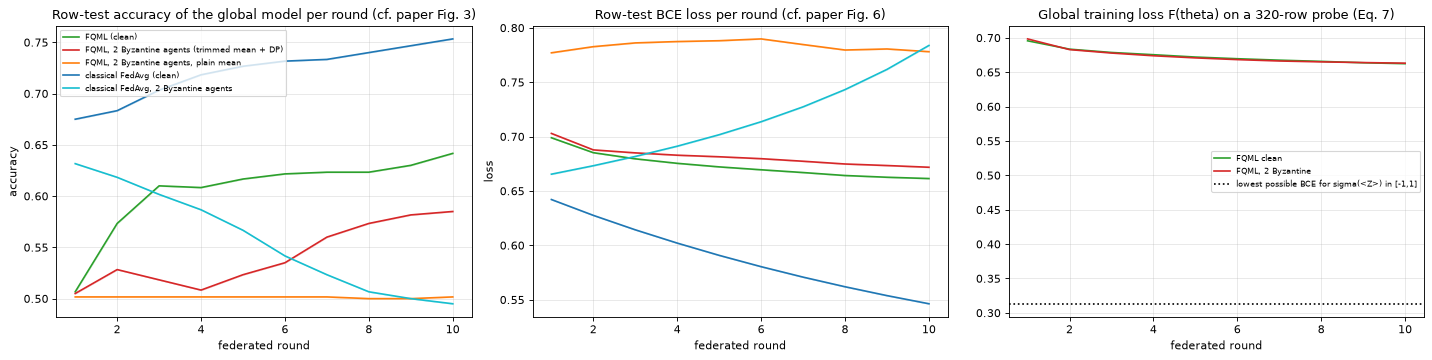

In [20]:
# ---- paper Fig. 3 / Fig. 6 analogue: accuracy and loss over federated rounds, clean vs adversarial ----
def band(method, col):
    arr = np.array([RES[method][s]["res"]["curve"][col].to_numpy() for s in RES[method]])
    return arr.mean(0), arr.std(0)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
styles = [("FQML", "tab:green", "FQML (clean)"), ("FQML|byz", "tab:red", "FQML, 2 Byzantine agents (trimmed mean + DP)"),
          ("FQML-mean|byz", "tab:orange", "FQML, 2 Byzantine agents, plain mean"), ("FedAvg", "tab:blue", "classical FedAvg (clean)"),
          ("FedAvg|byz", "tab:cyan", "classical FedAvg, 2 Byzantine agents")]
for nm, c, lab in styles:
    for j, col in enumerate(("acc", "loss")):
        mu, sd = band(nm, col); r_ = np.arange(1, len(mu) + 1)
        ax[j].plot(r_, mu, color=c, label=lab); ax[j].fill_between(r_, mu - sd, mu + sd, color=c, alpha=0.15)
ax[0].set_title("Row-test accuracy of the global model per round (cf. paper Fig. 3)"); ax[0].set_xlabel("federated round"); ax[0].set_ylabel("accuracy"); ax[0].legend(fontsize=7)
ax[1].set_title("Row-test BCE loss per round (cf. paper Fig. 6)"); ax[1].set_xlabel("federated round"); ax[1].set_ylabel("loss")
mu, sd = band("FQML", "train_loss"); r_ = np.arange(1, len(mu) + 1)
mu2, _ = band("FQML|byz", "train_loss")
ax[2].plot(r_, mu, color="tab:green", label="FQML clean"); ax[2].plot(r_, mu2, color="tab:red", label="FQML, 2 Byzantine")
ax[2].axhline(np.log(1 + np.exp(-1)), color="k", ls=":", label="lowest possible BCE for sigma(<Z>) in [-1,1]")
ax[2].set_title("Global training loss F(theta) on a 320-row probe (Eq. 7)"); ax[2].set_xlabel("federated round"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

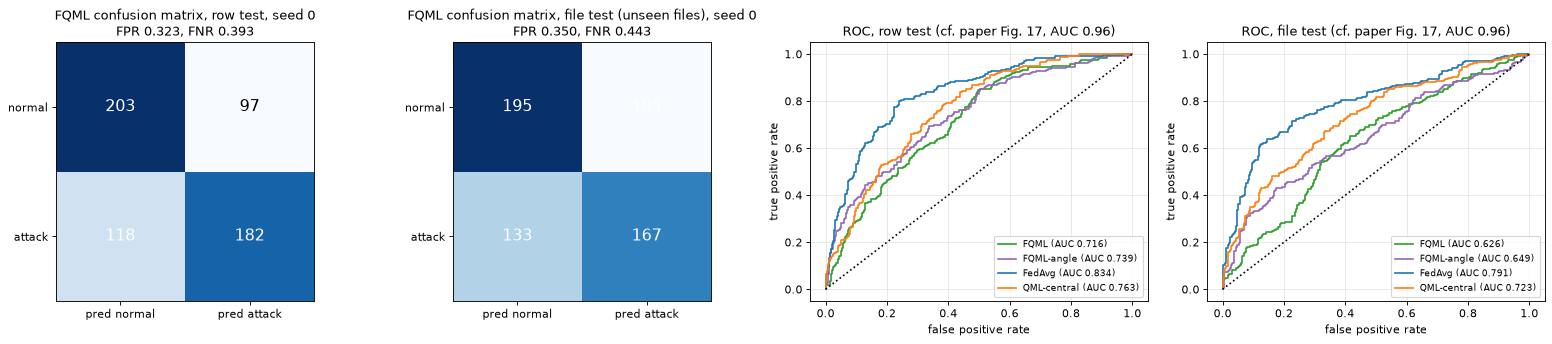

In [21]:
# ---- paper Fig. 7 / 16 (confusion matrices), Fig. 17 (ROC) ----
fig, ax = plt.subplots(1, 4, figsize=(20, 4.4))
for a, (set_, ttl) in zip(ax[:2], (("row", "row test"), ("file", "file test (unseen files)"))):
    m_ = RES["FQML"][RUN_SEEDS[0]]["ev"]["clean"][set_]
    cm = np.array([[m_["tn"], m_["fp"]], [m_["fn"], m_["tp"]]])
    a.imshow(cm, cmap="Blues"); a.grid(False)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
    a.set_xticks([0, 1]); a.set_xticklabels(["pred normal", "pred attack"]); a.set_yticks([0, 1]); a.set_yticklabels(["normal", "attack"])
    a.set_title(f"FQML confusion matrix, {ttl}, seed {RUN_SEEDS[0]}\nFPR {m_['FPR']:.3f}, FNR {m_['FNR']:.3f}")
for a, (set_, key) in zip(ax[2:], (("row", "scores_row"), ("file", "scores_file"))):
    for nm, c in (("FQML", "tab:green"), ("FQML-angle", "tab:purple"), ("FedAvg", "tab:blue"), ("QML-central", "tab:orange")):
        sc = RES[nm][RUN_SEEDS[0]]["ev"][key]
        fpr_, tpr_, _ = roc_curve(Y_SET[set_], sc); a.plot(fpr_, tpr_, color=c, label=f"{nm} (AUC {roc_auc_score(Y_SET[set_], sc):.3f})")
    a.plot([0, 1], [0, 1], "k:"); a.set_xlabel("false positive rate"); a.set_ylabel("true positive rate"); a.set_title(f"ROC, {set_} test (cf. paper Fig. 17, AUC 0.96)"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

Fig. 12 analogue: row-test accuracy (%), FGSM eps = 0.1 sigma, 2 of 10 agents Byzantine (sign-flip x5); degradation = clean - (Byzantine-trained, then FGSM)


,clean,byzantine_trained,clean_then_FGSM,byzantine_then_FGSM,degradation_pts
FQML,64.2 +- 0.0,58.5 +- 0.0,54.3 +- 0.0,45.5 +- 0.0,18.7
FQML-mean,n/a,50.2 +- 0.0,n/a,50.0 +- 0.0,NaN
QML-central,69.2 +- 0.0,n/a,51.0 +- 0.0,n/a,NaN
QML-local,59.5 +- 0.0,n/a,n/a,n/a,NaN
FedAvg,75.3 +- 0.0,49.5 +- 0.0,48.8 +- 0.0,35.0 +- 0.0,40.3
FedProx,75.3 +- 0.0,49.8 +- 0.0,48.8 +- 0.0,35.2 +- 0.0,40.2
SCAFFOLD,75.5 +- 0.0,54.3 +- 0.0,48.8 +- 0.0,28.7 +- 0.0,46.8
FedAvg+DP+TM,75.2 +- 0.0,66.0 +- 0.0,49.0 +- 0.0,47.5 +- 0.0,27.7


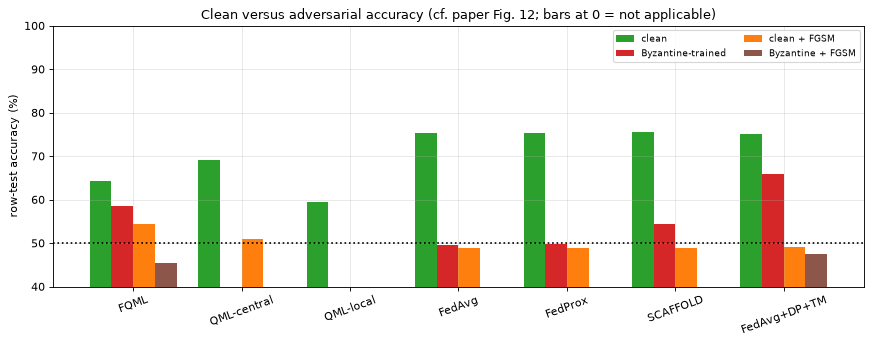

In [22]:
# ---- paper Fig. 12 analogue: clean vs adversarial accuracy of every method ----
def acc_triplet(base):
    cl = ms(base, "row", "ACC")
    by = ms(base + "|byz", "row", "ACC") if (base + "|byz") in RES else (np.nan, np.nan)
    fg = ms(base, "row", "ACC", eps=ATTACK_EPS)
    bf = ms(base + "|byz", "row", "ACC", eps=ATTACK_EPS) if (base + "|byz") in RES else (np.nan, np.nan)
    return cl, by, fg, bf
F12 = {}
for nm in ("FQML", "FQML-mean", "QML-central", "QML-local", "FedAvg", "FedProx", "SCAFFOLD", "FedAvg+DP+TM"):
    if nm == "FQML-mean":
        F12[nm] = ((np.nan, np.nan), ms("FQML-mean|byz", "row", "ACC"), (np.nan, np.nan), ms("FQML-mean|byz", "row", "ACC", eps=ATTACK_EPS))
    elif nm in ("QML-central", "QML-local"):
        F12[nm] = (ms(nm, "row", "ACC"), (np.nan, np.nan), ms(nm, "row", "ACC", eps=ATTACK_EPS) if RES[nm][RUN_SEEDS[0]]["ev"]["fgsm"] else (np.nan, np.nan), (np.nan, np.nan))
    else:
        F12[nm] = acc_triplet(nm)
T12 = pd.DataFrame({nm: dict(clean=fmt(v[0]), byzantine_trained=fmt(v[1]), clean_then_FGSM=fmt(v[2]), byzantine_then_FGSM=fmt(v[3]),
                             degradation_pts=(round(v[0][0] - v[3][0], 1) if not np.isnan(v[3][0]) and not np.isnan(v[0][0]) else np.nan)) for nm, v in F12.items()}).T
print(f"Fig. 12 analogue: row-test accuracy (%), FGSM eps = {ATTACK_EPS} sigma, 2 of 10 agents Byzantine (sign-flip x{BYZ_GAIN:g}); degradation = clean - (Byzantine-trained, then FGSM)")
display(T12)
names_ = ["FQML", "QML-central", "QML-local", "FedAvg", "FedProx", "SCAFFOLD", "FedAvg+DP+TM"]
fig, ax = plt.subplots(figsize=(11, 4.4)); wd = 0.2
for j, (key_i, lab, c) in enumerate(((0, "clean", "tab:green"), (1, "Byzantine-trained", "tab:red"), (2, "clean + FGSM", "tab:orange"), (3, "Byzantine + FGSM", "tab:brown"))):
    ax.bar(np.arange(len(names_)) + (j - 1.5) * wd, [F12[n][key_i][0] if not np.isnan(F12[n][key_i][0]) else 0 for n in names_], wd, yerr=[F12[n][key_i][1] if not np.isnan(F12[n][key_i][1]) else 0 for n in names_], color=c, label=lab)
ax.axhline(50, color="k", ls=":"); ax.set_xticks(np.arange(len(names_))); ax.set_xticklabels(names_, rotation=20); ax.set_ylim(40, 100); ax.set_ylabel("row-test accuracy (%)")
ax.set_title("Clean versus adversarial accuracy (cf. paper Fig. 12; bars at 0 = not applicable)"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

### Robustness against the input perturbation, per-agent variance and communication cost

* **Fig. 8 analogue.** The same trained global models are attacked with FGSM of growing size $\epsilon$ (in units of the training standard deviation of every PCA feature). White-box: the gradient comes from each model itself.
* **Fig. 15 analogue.** Accuracy of the ten agents' *local* models (the global angles after the agent's 5 local epochs of the last round) on the row test, compared with ten agents that never federate.
* **Fig. 4 analogue.** Bytes uploaded per agent and round. The paper's "about 500 KB per round" is the size of *encrypted* updates in a PySyft/TFF stack; here only the raw 32-bit parameter vectors are counted.

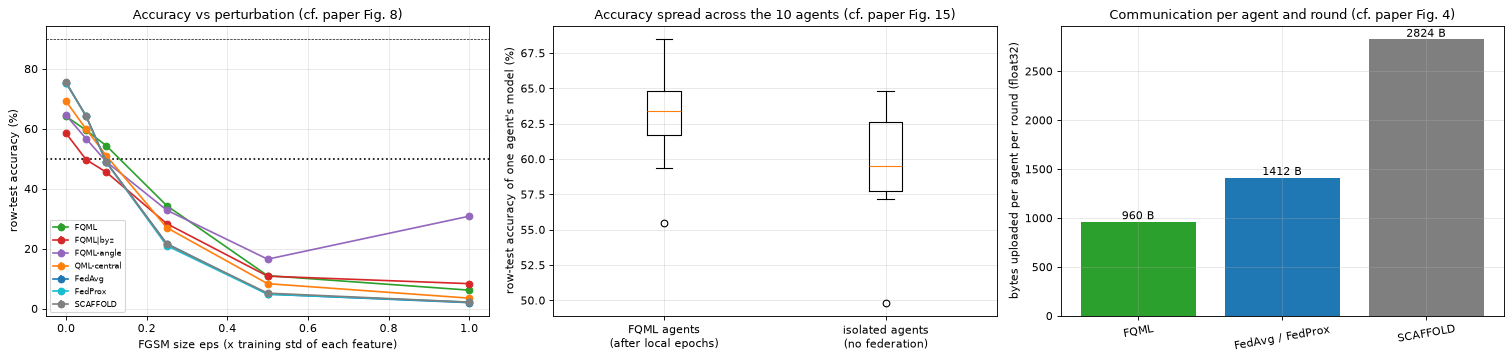

FQML uploads 240 numbers per agent and round, the classical 20-16-1 MLP uploads 353: 32.0 % fewer bytes (paper: 28.6 % less than classical FL, about 500 KB per round with encryption overhead).
agent accuracies, FQML local models: mean 62.9 % (IQR 61.7 to 64.8); isolated agents: mean 59.5 % (IQR 57.8 to 62.6)


In [23]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))
for nm, c in (("FQML", "tab:green"), ("FQML|byz", "tab:red"), ("FQML-angle", "tab:purple"), ("QML-central", "tab:orange"), ("FedAvg", "tab:blue"), ("FedProx", "tab:cyan"), ("SCAFFOLD", "tab:gray")):
    mu = [ms(nm, "row", "ACC", eps=e)[0] for e in EPS_ADV_GRID]; sd = [ms(nm, "row", "ACC", eps=e)[1] for e in EPS_ADV_GRID]
    ax[0].errorbar(EPS_ADV_GRID, mu, yerr=sd, color=c, marker="o", label=nm)
ax[0].set_xlabel("FGSM size eps (x training std of each feature)"); ax[0].set_ylabel("row-test accuracy (%)"); ax[0].axhline(50, color="k", ls=":"); ax[0].axhline(90, color="k", ls="--", lw=0.6)
ax[0].set_title("Accuracy vs perturbation (cf. paper Fig. 8)"); ax[0].legend(fontsize=7)
Sd = STATES["amplitude"]["sets"]["row"]; yrow = Y_SET["row"]
fq_loc = RES["FQML"][RUN_SEEDS[0]]["res"]["local_final"]
fs_ = q_forward(fq_loc, np.repeat(Sd[None], len(fq_loc), 0), READOUT)[0]
acc_fed_loc = [float(np.mean((fs_[c] > 0) == yrow)) * 100 for c in range(len(fq_loc))]
iso = RES["QML-local"][RUN_SEEDS[0]]["res"]["thetas"]
fs_i = q_forward(iso, np.repeat(Sd[None], len(iso), 0), READOUT)[0]
acc_iso = [float(np.mean((fs_i[c] > 0) == yrow)) * 100 for c in range(len(iso))]
ax[1].boxplot([acc_fed_loc, acc_iso]); ax[1].set_xticklabels(["FQML agents\n(after local epochs)", "isolated agents\n(no federation)"]); ax[1].set_ylabel("row-test accuracy of one agent's model (%)")
ax[1].set_title("Accuracy spread across the 10 agents (cf. paper Fig. 15)")
PARAMS = {"FQML (VQC, 240 angles)": 240, "FedAvg / FedProx (MLP, 353 weights)": N_MLP, "SCAFFOLD (weights + control variate)": 2 * N_MLP}
byts = {k: v * 4 for k, v in PARAMS.items()}
ax[2].bar(range(len(byts)), [v for v in byts.values()], color=["tab:green", "tab:blue", "tab:gray"])
for i, v in enumerate(byts.values()):
    ax[2].text(i, v, f"{v} B", ha="center", va="bottom")
ax[2].set_xticks(range(len(byts))); ax[2].set_xticklabels([k.split(" (")[0] for k in byts], rotation=10); ax[2].set_ylabel("bytes uploaded per agent per round (float32)")
ax[2].set_title("Communication per agent and round (cf. paper Fig. 4)")
plt.tight_layout(); plt.show()
COMM_SAVING = 1 - 240 / N_MLP
print(f"FQML uploads 240 numbers per agent and round, the classical 20-16-1 MLP uploads {N_MLP}: {100 * COMM_SAVING:.1f} % fewer bytes (paper: 28.6 % less than classical FL, about 500 KB per round with encryption overhead).")
print(f"agent accuracies, FQML local models: mean {np.mean(acc_fed_loc):.1f} % (IQR {np.percentile(acc_fed_loc, 25):.1f} to {np.percentile(acc_fed_loc, 75):.1f}); isolated agents: mean {np.mean(acc_iso):.1f} % (IQR {np.percentile(acc_iso, 25):.1f} to {np.percentile(acc_iso, 75):.1f})")

## 10. Sweeps: privacy budget, circuit depth, number of agents

One seed (`RUN_SEEDS[0]`) and `SWEEP_ROUNDS` rounds per point; the paper's figures use 100 rounds and 5 seeds. The **privacy sweep** clips every coordinate of the update to $[-S,S]$ ($S=0.05$) and adds $\mathrm{Lap}(0,S/\epsilon)$, which is the paper's calibration rule $\sigma=S/\epsilon$ (Sec. 7.8); as stated in the table at the top this is *not* a formal $\epsilon$-DP guarantee for the whole vector. The classical twin (FedAvg + the same clipping, noise and trimmed mean) is swept alongside.

In [24]:
SW = RUN_SEEDS[0]
T_SW = time.time()
print("--- privacy sweep ---")
run_q("sweep-noDP", SW, rounds=SWEEP_ROUNDS, agg="trimmed", dp_sigma=0.0)
for e in DP_EPS_GRID:
    run_q(f"sweep-eps{e}", SW, rounds=SWEEP_ROUNDS, agg="trimmed", dp_clip=DP_CLIP, dp_sigma=DP_CLIP / e)
    run_c(f"sweep-fedavg-eps{e}", SW, rounds=SWEEP_ROUNDS, algo="fedavg", agg="trimmed", dp_clip=DP_CLIP, dp_sigma=DP_CLIP / e)
run_c("sweep-fedavg-noDP", SW, rounds=SWEEP_ROUNDS, algo="fedavg", agg="trimmed")
print("--- depth sweep ---")
for L_ in DEPTH_GRID:
    run_q(f"sweep-L{L_}", SW, rounds=SWEEP_ROUNDS, L=L_, agg="trimmed", dp_sigma=DP_SIGMA)
print("--- agents sweep ---")
for N_ in sorted(set(AGENT_GRID + [N_AGENTS])) if AGENT_GRID else []:
    run_q(f"sweep-N{N_}", SW, agents=N_, rounds=SWEEP_ROUNDS, agg="trimmed", dp_sigma=DP_SIGMA)
print(f"sweeps done in {(time.time() - T_SW) / 60:.1f} min")

--- privacy sweep ---


  [sweep-noDP       seed 0] row ACC 0.613 F1 0.605 AUC 0.685 | file ACC 0.580 | FGSM(eps=0.1) ACC 0.517 | 36 s


  [sweep-eps0.5     seed 0] row ACC 0.613 F1 0.631 AUC 0.647 | file ACC 0.553 | FGSM(eps=0.1) ACC 0.395 | 38 s


  [sweep-fedavg-eps0.5 seed 0] row ACC 0.705 F1 0.673 AUC 0.795 | file ACC 0.698 | FGSM ACC 0.487 | 1 s


  [sweep-eps8.0     seed 0] row ACC 0.618 F1 0.611 AUC 0.680 | file ACC 0.575 | FGSM(eps=0.1) ACC 0.475 | 35 s


...

  [sweep-fedavg-noDP seed 0] row ACC 0.737 F1 0.711 AUC 0.812 | file ACC 0.725 | FGSM ACC 0.475 | 1 s


--- depth sweep ---


  [sweep-L2         seed 0] row ACC 0.575 F1 0.522 AUC 0.569 | file ACC 0.592 | FGSM(eps=0.1) ACC 0.368 | 9 s


  [sweep-L10        seed 0] row ACC 0.622 F1 0.615 AUC 0.684 | file ACC 0.578 | FGSM(eps=0.1) ACC 0.512 | 29 s


--- agents sweep ---
sweeps done in 2.5 min


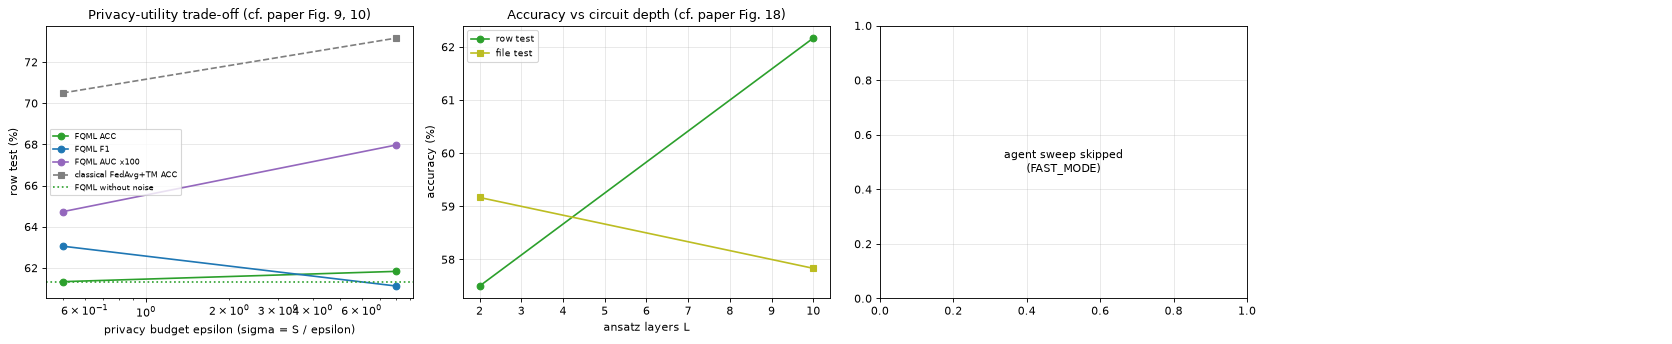

,epsilon,FQML ACC,FQML F1,FedAvg+TM ACC
0,no noise,61.3,60.5,73.7
1,0.5,61.3,63.1,70.5
2,8.0,61.8,61.1,73.2


,layers,row ACC,file ACC
0,2,57.5,59.2
1,10,62.2,57.8


In [25]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.4))
def sw(m_, metric="ACC", scale=100.0):
    return RES[m_][SW]["ev"]["clean"]["row"][metric] * scale
epsx = DP_EPS_GRID
for metric, c in (("ACC", "tab:green"), ("F1", "tab:blue"), ("AUC", "tab:purple")):
    ax[0].plot(epsx, [sw(f"sweep-eps{e}", metric) for e in epsx], marker="o", color=c, label=f"FQML {metric}" + (" x100" if metric == "AUC" else ""))
ax[0].plot(epsx, [sw(f"sweep-fedavg-eps{e}") for e in epsx], marker="s", ls="--", color="tab:gray", label="classical FedAvg+TM ACC")
ax[0].axhline(sw("sweep-noDP"), color="tab:green", ls=":", label="FQML without noise"); ax[0].set_xscale("log"); ax[0].set_xlabel("privacy budget epsilon (sigma = S / epsilon)"); ax[0].set_ylabel("row test (%)")
ax[0].set_title("Privacy-utility trade-off (cf. paper Fig. 9, 10)"); ax[0].legend(fontsize=7)
ax[1].plot(DEPTH_GRID, [sw(f"sweep-L{L_}") for L_ in DEPTH_GRID], marker="o", color="tab:green", label="row test"); ax[1].plot(DEPTH_GRID, [RES[f"sweep-L{L_}"][SW]["ev"]["clean"]["file"]["ACC"] * 100 for L_ in DEPTH_GRID], marker="s", color="tab:olive", label="file test")
ax[1].set_xlabel("ansatz layers L"); ax[1].set_ylabel("accuracy (%)"); ax[1].set_title("Accuracy vs circuit depth (cf. paper Fig. 18)"); ax[1].legend(fontsize=8)
Ns = sorted(set(AGENT_GRID + [N_AGENTS])) if AGENT_GRID else []
if Ns:
    ax[2].plot(Ns, [sw(f"sweep-N{N_}") for N_ in Ns], marker="o", color="tab:green"); ax[2].set_xlabel("number of agents (fixed rows per agent)"); ax[2].set_ylabel("row-test accuracy (%)")
    ax[2].set_title("Accuracy vs agents (cf. paper Fig. 11)")
    tpr_ = [RES[f"sweep-N{N_}"][SW]["res"]["curve"]["time"].iloc[-1] / SWEEP_ROUNDS for N_ in Ns]
    ax[3].plot(Ns, tpr_, marker="o", color="tab:red"); ax[3].set_xlabel("number of agents"); ax[3].set_ylabel("simulation seconds per federated round"); ax[3].set_title("Time per round (cf. paper Fig. 14; simulator wall clock)")
else:
    ax[2].text(0.5, 0.5, "agent sweep skipped\n(FAST_MODE)", ha="center", va="center"); ax[3].axis("off")
plt.tight_layout(); plt.show()
sweep_tab = pd.DataFrame({"epsilon": ["no noise"] + DP_EPS_GRID, "FQML ACC": [sw("sweep-noDP")] + [sw(f"sweep-eps{e}") for e in DP_EPS_GRID],
                          "FQML F1": [sw("sweep-noDP", "F1")] + [sw(f"sweep-eps{e}", "F1") for e in DP_EPS_GRID],
                          "FedAvg+TM ACC": [sw("sweep-fedavg-noDP")] + [sw(f"sweep-fedavg-eps{e}") for e in DP_EPS_GRID]}).round(1)
display(sweep_tab)
display(pd.DataFrame({"layers": DEPTH_GRID, "row ACC": [round(sw(f"sweep-L{L_}"), 1) for L_ in DEPTH_GRID], "file ACC": [round(RES[f'sweep-L{L_}'][SW]['ev']['clean']['file']['ACC'] * 100, 1) for L_ in DEPTH_GRID]}))

### Convergence speed

The paper says (Sec. 5.5) that FQML "converges to $\le 1\%$ loss 38% faster" than the classical counterpart. A loss of 1% cannot be reached by the model of Eq. 17, because $\sigma(\langle Z\rangle)\in[0.27,0.73]$ keeps the binary cross-entropy above $\ln(1+e^{-1})\approx0.31$ whatever the data (the dotted line in the loss plot). We therefore measure something that can be measured: the first round at which the mean row-test accuracy reaches 95% of the *lower* of the two final accuracies, for FQML and for the classical FedAvg with the same noise and trimmed mean.

In [26]:
def first_round(curve_mean, thr):
    hit = np.where(curve_mean >= thr)[0]
    return int(hit[0]) + 1 if len(hit) else None
mq, _ = band("FQML", "acc"); mc, _ = band("FedAvg+DP+TM", "acc"); mc0, _ = band("FedAvg", "acc")
thr = 0.95 * min(mq[-1], mc[-1])
rq, rc, rc0 = first_round(mq, thr), first_round(mc, thr), first_round(mc0, 0.95 * min(mq[-1], mc0[-1]))
print(f"target accuracy {thr:.3f} (95 % of the lower final accuracy): FQML reaches it in round {rq}, FedAvg+DP+TM in round {rc}; "
      f"plain FedAvg (target {0.95 * min(mq[-1], mc0[-1]):.3f}) in round {rc0}.")
CONV_FASTER = (None if (rq is None or rc is None) else (rc - rq) / rc)
print("FQML faster than FedAvg+DP+TM by", None if CONV_FASTER is None else f"{100 * CONV_FASTER:.0f} %", "(paper: 38 % to reach 1 % loss)")

target accuracy 0.610 (95 % of the lower final accuracy): FQML reaches it in round 3, FedAvg+DP+TM in round 1; plain FedAvg (target 0.610) in round 1.
FQML faster than FedAvg+DP+TM by -200 % (paper: 38 % to reach 1 % loss)


## 11. Paper versus this notebook: verdict per claim

Rules (from the repository convention): a number is **reproduced** when this notebook is within 2 accuracy points (0.02 for F1 and AUC) of the paper's number, **not reached** when it is lower by more, **exceeded** when higher by more; orderings and qualitative claims are checked directly; claims that need data, hardware or noise models that were not available are **cannot be checked**. Remember the data substitution: the paper's synthetic and IEEE-39-bus data are not public, so the absolute numbers are a test of the *method on real power-system data*, not of the paper's data.

In [27]:
def verdict_num(paper, ours, tol=2.0, nd=1):
    if ours is None or np.isnan(ours):
        return "cannot be checked"
    gap = ours - paper
    if abs(gap) <= tol: return f"reproduced (gap {gap:+.{nd}f})"
    return f"not reached (gap {gap:+.{nd}f})" if gap < 0 else f"exceeded (gap {gap:+.{nd}f})"

def mean_(method, set_="row", metric="ACC", eps=None, scale=100.0):
    return ms(method, set_, metric, eps, scale)[0]

rows = []
def add_row(claim, paper, ours, verdict):
    rows.append(dict(claim=claim, paper=paper, notebook=ours, verdict=verdict))

fq = lambda k, s="row", sc=100.0: mean_("FQML", s, k, None, sc)
# 1 clean accuracy
add_row("FQML clean accuracy >= 96.3 % (abstract; 96.1 in Table 1; 96 in Fig. 12)", "96.1 / 96.3", f"{fq('ACC'):.1f} (row test), {fq('ACC', 'file'):.1f} (file test)", verdict_num(96.1, fq("ACC")))
# 2 Table 1 metrics
for k, pv in (("Precision", 95.5), ("Recall", 94.9), ("F1", 95.2)):
    add_row(f"Table 1 FQML {k}", f"{pv}", f"{fq(k):.1f}", verdict_num(pv, fq(k)))
add_row("Table 1 FQML AUC", "0.968", f"{fq('AUC', 'row', 1.0):.3f}", verdict_num(0.968, fq("AUC", "row", 1.0), 0.02, 3))
add_row("Fig. 17 ROC AUC", "0.96", f"{fq('AUC', 'row', 1.0):.3f}", verdict_num(0.96, fq("AUC", "row", 1.0), 0.02, 3))
# 3 baselines
for nm, pa, pf in (("FedProx", 93.2, 91.2), ("SCAFFOLD", 92.4, 90.7)):
    add_row(f"Table 1 {nm} accuracy / F1", f"{pa} / {pf}", f"{mean_(nm):.1f} / {mean_(nm, 'row', 'F1'):.1f}", verdict_num(pa, mean_(nm)))
fedprox_a, scaf_a, fq_a = mean_("FedProx"), mean_("SCAFFOLD"), fq("ACC")
add_row("Ordering in Table 1: FQML > FedProx > SCAFFOLD (accuracy)", "96.1 > 93.2 > 92.4", f"{fq_a:.1f} / {fedprox_a:.1f} / {scaf_a:.1f}", "reproduced" if fq_a > fedprox_a > scaf_a else "not reached")
add_row("FQML ~3 points above the strongest federated baseline (Table 1)", "+2.9", f"{fq_a - max(fedprox_a, scaf_a):+.1f}", verdict_num(2.9, fq_a - max(fedprox_a, scaf_a)))
# 4 encoding
amp_a, ang_a = fq("ACC"), mean_("FQML-angle")
add_row("Table 2 amplitude accuracy / F1 / AUC", "96.2 / 95.1 / 0.973", f"{amp_a:.1f} / {fq('F1'):.1f} / {fq('AUC', 'row', 1.0):.3f}", verdict_num(96.2, amp_a))
add_row("Table 2 angle accuracy / F1 / AUC", "94.7 / 93.8 / 0.964", f"{ang_a:.1f} / {mean_('FQML-angle', 'row', 'F1'):.1f} / {mean_('FQML-angle', 'row', 'AUC', None, 1.0):.3f}", verdict_num(94.7, ang_a))
add_row("Amplitude encoding beats angle encoding by 1.5 points", "+1.5", f"{amp_a - ang_a:+.1f}", "reproduced" if (amp_a - ang_a) > 0 and abs((amp_a - ang_a) - 1.5) <= 2.0 else ("exceeded" if amp_a - ang_a > 3.5 else "not reached (angle is better or equal)"))
# 5 adversarial
adv_a = mean_("FQML|byz", "row", "ACC", ATTACK_EPS); byz_a = mean_("FQML|byz"); fg_a = mean_("FQML", "row", "ACC", ATTACK_EPS)
add_row("Adversarial accuracy ~88 % (Sec. 7.1) / 93 % (Fig. 12): Byzantine-trained then FGSM", "88 / 93", f"{adv_a:.1f} (components: Byzantine only {byz_a:.1f}, FGSM only {fg_a:.1f})", verdict_num(88.0, adv_a))
add_row("Degradation clean -> adversarial <= 7 points", "<= 7", f"{fq_a - adv_a:.1f}", "reproduced" if fq_a - adv_a <= 7 else "not reached")
add_row("Byzantine robustness is due to the trimmed mean (plain mean breaks)", "qualitative", f"trimmed {byz_a:.1f} vs mean {mean_('FQML-mean|byz'):.1f} (clean {fq_a:.1f})", "reproduced" if byz_a - mean_("FQML-mean|byz") > 5 else "not reached (aggregator makes little difference here)")
others = {n: mean_(n) for n in ("QML-central", "QML-local", "FedAvg", "FedProx", "SCAFFOLD")}
add_row("Fig. 12: FQML has the highest clean accuracy of all methods", "96 vs lower", f"FQML {fq_a:.1f}; " + ", ".join(f"{k} {v:.1f}" for k, v in others.items()), "reproduced" if fq_a >= max(others.values()) else "not reached")
deg = {n: mean_(n) - mean_(n + "|byz", "row", "ACC", ATTACK_EPS) for n in ("FedAvg", "FedProx", "SCAFFOLD")}
add_row("Fig. 12: FQML has the smallest degradation under attack", "3 points", f"FQML {fq_a - adv_a:.1f}; " + ", ".join(f"{k} {v:.1f}" for k, v in deg.items()), "reproduced" if fq_a - adv_a <= min(deg.values()) else "not reached")
# 6 FGSM sweep
e_lo = EPS_ADV_GRID[2]
acc_lo = mean_("FQML", "row", "ACC", e_lo)
mono = all(ms("FQML", "row", "ACC", eps=EPS_ADV_GRID[i])[0] >= ms("FQML", "row", "ACC", eps=EPS_ADV_GRID[i + 1])[0] - 1.5 for i in range(len(EPS_ADV_GRID) - 1))
add_row("Fig. 8: accuracy > 90 % for low-to-moderate perturbation", "> 90", f"{acc_lo:.1f} at eps={e_lo} (clean {fq_a:.1f})", "reproduced" if acc_lo > 90 else "not reached")
add_row("Fig. 8: graceful (monotone) degradation with eps", "qualitative", "monotone within 1.5 points" if mono else "non-monotone", "reproduced" if mono else "not reached")
# 7 privacy
eps_acc = {e: sw(f"sweep-eps{e}") for e in DP_EPS_GRID}
add_row("Fig. 9: accuracy stays >= 85 % even for strict privacy (eps <= 1)", ">= 85", f"{eps_acc[min(DP_EPS_GRID)]:.1f} at eps={min(DP_EPS_GRID)}", "reproduced" if eps_acc[min(DP_EPS_GRID)] >= 85 else "not reached")
add_row("Fig. 9: accuracy increases with epsilon and plateaus (90-92 %)", "rise then plateau", " / ".join(f"{e}:{v:.1f}" for e, v in eps_acc.items()), "reproduced" if eps_acc[max(DP_EPS_GRID)] >= eps_acc[min(DP_EPS_GRID)] + 1 else "not reached (flat or noisy)")
# 8 depth
dacc = {L_: sw(f"sweep-L{L_}") for L_ in DEPTH_GRID}
add_row("Fig. 18: accuracy improves with depth, saturating at 8-10 layers", "rise then plateau", " / ".join(f"L{k}:{v:.1f}" for k, v in dacc.items()), "reproduced" if dacc[max(DEPTH_GRID)] >= dacc[min(DEPTH_GRID)] + 1 else "not reached (no depth gain)")
# 9 scalability
if AGENT_GRID:
    nacc = {N_: sw(f"sweep-N{N_}") for N_ in sorted(set(AGENT_GRID + [N_AGENTS]))}
    add_row("Fig. 11: accuracy drops by < 3 % when agents grow (5 -> 80 in the paper, 5 -> 20 here)", "< 3", " / ".join(f"N{k}:{v:.1f}" for k, v in nacc.items()), "reproduced" if nacc[min(nacc)] - nacc[max(nacc)] < 3 else "not reached")
else:
    add_row("Fig. 11: accuracy drops by < 3 % when agents grow", "< 3", "agent sweep skipped in FAST_MODE", "cannot be checked")
# 10 convergence, communication, structure
add_row("Sec. 5.5: converges to <= 1 % loss 38 % faster than classical", "38 % faster", "BCE of sigma(<Z>) cannot go below 0.31; rounds to 95 % of final accuracy: FQML " + str(rq) + " vs FedAvg+DP+TM " + str(rc), "cannot be checked (not literally testable)")
add_row("Abstract: communication overhead 28.6 % lower than classical FL; ~500 KB per round", "28.6 % / 500 KB", f"{100 * COMM_SAVING:.1f} % fewer parameters than the 353-weight MLP; 960 B per agent and round", "cannot be checked (KB figure includes encryption overhead); parameter-count saving is of the same size")
add_row("8 qubits, 10 layers, 240 trainable angles (Sec. 6.3)", "8 / 10 / 240", "8 / 10 / 240 (asserted equal to the PennyLane QNode)", "reproduced (by construction)")
add_row("Fig. 13: smooth accuracy decline under depolarising / damping / readout noise; error mitigation recovers some", "qualitative", "not run (needs a density-matrix training loop)", "cannot be checked")
add_row("Real quantum hardware", "future work", "none (neither does the paper)", "not applicable")
add_row("Fig. 15: narrow IQR of agent accuracies", "narrow", f"IQR {np.percentile(acc_fed_loc, 25):.1f}-{np.percentile(acc_fed_loc, 75):.1f}", "reproduced" if np.percentile(acc_fed_loc, 75) - np.percentile(acc_fed_loc, 25) <= 3 else "not reached")
VERD = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 250)
display(VERD)
print(VERD.verdict.str.split(" ").str[0].value_counts().to_dict())

,claim,paper,notebook,verdict
0,FQML clean accuracy >= 96.3 % (abstract; 96.1 in Table 1; 96 in Fig. 12),96.1 / 96.3,"64.2 (row test), 60.3 (file test)",not reached (gap -31.9)
1,Table 1 FQML Precision,95.5,65.2,not reached (gap -30.3)
2,Table 1 FQML Recall,94.9,60.7,not reached (gap -34.2)
3,Table 1 FQML F1,95.2,62.9,not reached (gap -32.3)
4,Table 1 FQML AUC,0.968,0.716,not reached (gap -0.252)
5,Fig. 17 ROC AUC,0.96,0.716,not reached (gap -0.244)
6,Table 1 FedProx accuracy / F1,93.2 / 91.2,75.3 / 73.3,not reached (gap -17.9)
7,Table 1 SCAFFOLD accuracy / F1,92.4 / 90.7,75.5 / 73.4,not reached (gap -16.9)
8,Ordering in Table 1: FQML > FedProx > SCAFFOLD (accuracy),96.1 > 93.2 > 92.4,64.2 / 75.3 / 75.5,not reached
9,FQML ~3 points above the strongest federated baseline (Table 1),+2.9,-11.3,not reached (gap -14.2)


{'not': 21, 'reproduced': 5, 'cannot': 4}


## 12. Reading the paper critically

0. **What the committed run shows (FAST_MODE, 1 seed, 10 rounds, 640 training rows).** On the real test-bed data FQML reaches 64.2% row-test and 60.3% file-test accuracy (AUC 0.72 / 0.63), far below the paper's 96.1%; the classical federated twins on the same 20 features reach about 75%, and a centralised random forest or logistic regression 86 to 88%. The paper's *qualitative* robustness story is partly visible: with two sign-flipping agents the trimmed mean keeps FQML at 58.5% while the plain mean collapses it to 50.2% (chance), and under FGSM (size 0.1 sigma) FQML loses fewer points in absolute terms than the classical models, but it also starts from a much lower accuracy, so this is no evidence of extra robustness; the FQML > FedProx > SCAFFOLD ordering and the amplitude advantage over angle encoding are not reproduced, and the privacy-utility curve is flat (the Laplace noise has no visible effect at these update sizes, so the sweep says nothing about privacy). With 64 rows per agent and 10 rounds these are one-seed numbers with sampling noise of several points, so only gaps of 10 points or more should be trusted.
1. **The data are synthetic and unpublished, the case study is unpublished.** Every headline number (96.1%, 0.968 AUC, the margins of 3 points over FedProx and SCAFFOLD, the 1.5-point amplitude advantage) is measured on data the authors generated themselves, with a dataset in which attack features are probably separable by construction; no code, data or seeds are released. On real test-bed measurements the tasks are much harder (see the classical references above, and note how far the file test is below the row test).
2. **A row-level test set overstates generalisation.** Rows of one scenario are near-duplicates, so a random split rewards memorising scenarios. The notebook reports the unseen-file test next to the row test; the quantum models lose 3 to 4 points there (FQML 64.2 to 60.3), while the random forest and logistic regression do not (they are already high and the unseen files here are similar in distribution). The *natural-fault test* (attack versus natural faults) is at or below chance for every classical reference (45 to 49%), which shows that a detector trained on "normal versus attack" cannot tell an attack from a short circuit; the paper's synthetic data never poses that question.
3. **"Adversarial" is never defined as one experiment.** Sec. 7.1 calls it false-data injection or poisoning, Sec. 3.3 an $\epsilon$-bounded FGSM perturbation, Sec. 6.5 two Byzantine agents; $\epsilon$ is never given, and the headline adversarial numbers disagree with each other (about 88% in Sec. 7.1, 93% in Fig. 12 for what is described as the same model; "$\le7\%$" degradation in the conclusions versus 96 - 93 = 3 in Fig. 12). We report Byzantine and FGSM separately and combined.
4. **The privacy axis does not carry the guarantee it names.** The sweep sets $\sigma=S/\epsilon$ for a clipping constant $S$ that is "chosen to preserve more than 95% of the update mass", but the sensitivity of a 240-dimensional update clipped *per coordinate* is $240\,S$ in the $\ell_1$ norm, not $S$; the stated $\epsilon$ is therefore off by two orders of magnitude, and no accountant or composition over 100 rounds is used. Accuracy above 85% "at $\epsilon\le1$" says that the noise is small compared with the signal, not that the training is private.
5. **The amplitude encoding is more expensive than the paper's depth plots show.** The 10-layer ansatz is the cheap part. Loading 20 numbers into an 8-qubit register costs roughly a thousand gates (see the depth table), so the claim "depth $\le10$, NISQ-ready" holds for the variational block only. The model also keeps $\ell_2$-normalised inputs, which discards the vector length even though the length is informative here (attacks have larger PCA norm); the angle encoding keeps it.
6. **The classical baselines are unspecified, and a quantum model with 240 angles is compared with a classical model of unknown size.** The 38%-faster-convergence and 28.6%-less-communication claims depend entirely on what the classical network is. Against a 353-parameter MLP the saving here is 32%; against a logistic regression on 20 features (21 parameters) the quantum model would send ten times more.
7. **No quantum advantage can be inferred.** Everything is simulated noise-free; the same task is solved by a centralised random forest or logistic regression on the same 20 features at equal or higher accuracy in this notebook; and the VQC output $\sigma(\langle Z\rangle)$ cannot get below a BCE of 0.31, which makes "converges to $\le1\%$ loss" meaningless for this model.
8. **Reproducibility.** Qiskit 0.45 is named but the code is not provided; PySyft and TensorFlow Federated are cited for the aggregation but the pseudo-code in Appendix A.3 is the only specification. Five seeds are claimed for every table; the standard deviations (0.3-0.6 points) are small for 100,000 samples but cannot be compared with ours, which use much smaller samples.

## 13. Exercises

1. **Where to measure.** Section 6 chose the measured qubit on a validation split. Repeat the comparison with the ring CNOT chain (add CNOT(7,0)) or with $\langle Z_0Z_7\rangle$ as the observable; change `PM` / `INV_PM` and the readout sign vector in the simulator and re-run the equivalence test of section 7. Does the choice matter more than the encoding?
2. **Bias amplitude.** The amplitude encoding discards the length of the PCA vector. Append a 21st entry equal to the median training norm before the $\ell_2$ normalisation and compare accuracy with the paper-literal encoding. Why can this help, and why does it cost nothing in qubits?
3. **Stronger attacks.** Replace the one-step FGSM by 10-step PGD (the paper names it as future work) and by a *label-flipping* attack at the two malicious agents. Which defence breaks first: the trimmed mean or the differential-privacy noise?
4. **A formal privacy budget.** Clip the $\ell_1$ norm of each update to $S$ and add Laplace noise of scale $S/\epsilon_{round}$ per coordinate; compose over the rounds with basic composition and re-draw the privacy-utility curve with the *true* total $\epsilon$. How large does it become at 30 rounds?
5. **Non-IID agents.** The paper says the agents hold "equal" slices. Give each agent only the scenarios of a few source files (a natural non-IID split of this dataset) and compare FQML, FedProx and SCAFFOLD again. Does SCAFFOLD's drift correction finally help?